# Geometrical optics: images, instruments and aberrations

Geometrical optics treats light as rays: straight lines in a homogeneous
medium that bend at interfaces according to Snell's law. It is the limit
of wave optics for wavelengths much smaller than everything else in the
system (notebook 00 (foundations and conventions) shows where it sits on the ladder from Maxwell's
equations down), and it is how lenses, cameras, microscopes and
telescopes are designed. This notebook is a first course in it, for
readers who have not met optics beyond school, or who want to see the
textbook formulas checked against an exact ray trace. Every formula
below is compared with `pyoptics.raytrace`, which traces real rays
through real surfaces with the exact law of refraction.

The path goes from the simplest approximation to the point where it
breaks down and wave optics takes over:

1. **rays and Snell's law**, the paraxial approximation and why it is
   only an approximation (one refracting sphere),
2. **the thin lens**: the lens equation, the lensmaker's equation and the
   magnification,
3. **real and virtual images**: ray diagrams with the three principal
   rays, and virtual images found by the ray tracer behind the lens,
4. **thick lenses and principal planes**: where to measure the focal
   length from, principal planes outside the glass (the telephoto lens),
   and what real rays make of the principal planes,
5. **stops and pupils**: the aperture stop, the entrance and exit
   pupils, chief and marginal rays, f-number and numerical aperture,
6. **simple optical instruments**: the magnifier, the compound
   microscope and the Kepler and Galilei telescopes, their magnifying
   power and their exit pupils,
7. **aberrations and the Seidel sums**: the five monochromatic
   aberrations of third order, a singlet bent for least spherical
   aberration, and the stop shift,
8. **wavefront error**: the optical path difference (OPD) over the pupil,
   rms and peak to valley, balancing with defocus, the Strehl ratio and
   the Maréchal and Rayleigh criteria; when a lens is diffraction
   limited.

Many later notebooks continue from here: 08 (ABCD matrices), 19 (the ray
tracer in depth), 44 (Seidel sums of a 42 surface lens), 102 (the sine
condition and the Lagrange invariant), 15 and 17 (Zernike polynomials,
PSF, MTF and Strehl ratio), 52 (how a microscope really forms an image)
and 97 (telescopes).

**Conventions.** Lengths are in mm, the light travels from left to right
along $+z$. Positions on the axis are *signed coordinates* measured from
the lens (Cartesian sign convention, as in the ray tracer and in
notebook 00, foundations and conventions): an object to the left of the lens has $a < 0$, an image
to the right $a' > 0$. Radii are positive if the centre of curvature
lies to the right of the surface, so a biconvex lens has $R_1 > 0$ and
$R_2 < 0$. Many school books count object distances positive instead,
$s_o = -a$ and $s_i = a'$; the lens equation $1/a' - 1/a = 1/f$ below
then becomes the familiar $1/s_o + 1/s_i = 1/f$. The wavelength is the
helium d line, 587.6 nm, at which the glass N-BK7 has $n = 1.5168$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import PowerNorm
from scipy.optimize import brentq, minimize_scalar

from pyoptics import raytrace as rt
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
lam = 587.6e-6                     # mm, the helium d line
n_bk7 = 1.5168                     # N-BK7 at the d line

## 1. Rays, Snell's law and the paraxial approximation

A ray that meets the interface between two media of refractive indices
$n$ and $n'$ at the angle of incidence $i$ (measured from the surface
normal) continues at the angle $i'$ with

$$n\sin i = n'\sin i' \qquad\text{(Snell's law)}.$$

For small angles $\sin i \approx i$, and Snell's law becomes linear,
$n\,i = n'\,i'$. This is the **paraxial approximation**, and almost
every formula of elementary optics (the lens equation, the focal
length, the magnification, the instruments of section 6) rests on it.
It is called *first order* optics because it keeps only the terms
linear in the angles and ray heights. Notebook 08 (ABCD matrices) writes it as 2×2
matrices.

How good is it? Take a single sphere of radius $R = 20$ mm between air
and glass and send in rays parallel to the axis. Paraxial optics puts
the focus at $z = n'R/(n' - n)$ behind the vertex, for all rays. The ray
tracer computes both the paraxial focus and the real rays:

In [2]:
R_ball = 20.0
one_surface = rt.System([rt.Surface(R_ball, 80.0, n_after=n_bk7, semi_diameter=12.0)], 0, lam)
p1 = one_surface.paraxial()
print("paraxial focus behind the vertex: n'R/(n' - n) = {:.3f} mm, paraxial ray trace {:.3f} mm"
      .format(n_bk7*R_ball/(n_bk7 - 1), p1.image_distance))

h_rays = np.linspace(-1, 1, 25)
b1 = one_surface.trace_pupil(0.0, 0.0, h_rays)
P, d = b1.points[1], b1.directions[1]
h = P[:, 1]
with np.errstate(invalid="ignore"):
    z_cross = P[:, 2] - h*d[:, 2]/d[:, 1]             # where each refracted ray crosses the axis
i_inc = np.degrees(np.arcsin(np.abs(h)/R_ball))         # angle of incidence on the sphere
for k in (15, 18, 21, 24):
    print("ray height {:5.2f} mm: angle of incidence {:5.1f} deg, crosses the axis at {:7.3f} mm "
          "({:+.3f} mm from the paraxial focus)".format(h[k], i_inc[k], z_cross[k], z_cross[k] - p1.image_distance))
for deg in (5, 10, 20, 30, 40):
    t = np.radians(deg)
    print("angle {:2d} deg: sin = {:.4f}, angle in rad = {:.4f}, relative error of sin(t) ~ t: {:.2%}"
          .format(deg, np.sin(t), t, t/np.sin(t) - 1))

paraxial focus behind the vertex: n'R/(n' - n) = 58.700 mm, paraxial ray trace 58.700 mm
ray height  3.00 mm: angle of incidence   8.6 deg, crosses the axis at  58.411 mm (-0.288 mm from the paraxial focus)
ray height  6.00 mm: angle of incidence  17.5 deg, crosses the axis at  57.531 mm (-1.169 mm from the paraxial focus)
ray height  9.00 mm: angle of incidence  26.7 deg, crosses the axis at  56.005 mm (-2.695 mm from the paraxial focus)
ray height 12.00 mm: angle of incidence  36.9 deg, crosses the axis at  53.722 mm (-4.978 mm from the paraxial focus)
angle  5 deg: sin = 0.0872, angle in rad = 0.0873, relative error of sin(t) ~ t: 0.13%
angle 10 deg: sin = 0.1736, angle in rad = 0.1745, relative error of sin(t) ~ t: 0.51%
angle 20 deg: sin = 0.3420, angle in rad = 0.3491, relative error of sin(t) ~ t: 2.06%
angle 30 deg: sin = 0.5000, angle in rad = 0.5236, relative error of sin(t) ~ t: 4.72%
angle 40 deg: sin = 0.6428, angle in rad = 0.6981, relative error of sin(t) ~ t: 8.61%


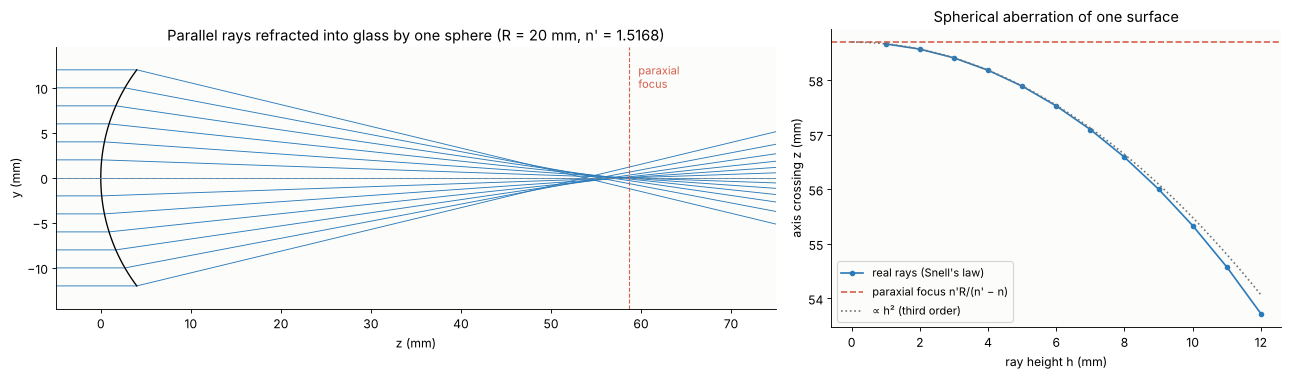

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained", width_ratios=[1.6, 1])
one_surface.draw(ax[0], n_rays=13, colors=[BLUE])
ax[0].set_aspect("equal", adjustable="box")
ax[0].axvline(p1.image_distance, color=RED, lw=1, ls="--")
ax[0].text(p1.image_distance + 1, 10, "paraxial\nfocus", color=RED, fontsize=10)
ax[0].set_xlim(-5, 75)
ax[0].set_title("Parallel rays refracted into glass by one sphere (R = 20 mm, n' = 1.5168)")
ax[0].set_xlabel("z (mm)")
ax[0].set_ylabel("y (mm)")
ok = h > 0
ax[1].plot(h[ok], z_cross[ok], "o-", color=BLUE, ms=4, label="real rays (Snell's law)")
ax[1].axhline(p1.image_distance, color=RED, ls="--", label="paraxial focus n'R/(n' − n)")
c2 = np.polyfit(h[ok][:4]**2, z_cross[ok][:4], 1)
hh = np.linspace(0, 12, 100)
ax[1].plot(hh, np.polyval(c2, hh**2), ":", color=GREY, label="∝ h² (third order)")
ax[1].set_xlabel("ray height h (mm)")
ax[1].set_ylabel("axis crossing z (mm)")
ax[1].set_title("Spherical aberration of one surface")
ax[1].legend(fontsize=10)
plt.show()

The paraxial focus of the trace and the formula agree exactly, but the
real rays do not meet there. The further from the axis a ray enters,
the shorter it focuses: 0.29 mm at a height of 3 mm, 5.0 mm at 12 mm,
where the angle of incidence is 37°. The ratio $\sin i/i$ is already
0.5 % off at 10° and 4.7 % at 30°. The paraxial focus is the limit of
the real axis crossings for vanishing ray height, and the departure
grows with $h^2$ at first (the dotted line). This **spherical
aberration** is the first *aberration* we meet: a property of the
real rays that first order optics leaves out. Sections 7 and 8 return
to it; until then we work paraxially, i.e. with thin pencils of rays
close to the axis, where the formulas are exact.

## 2. The thin lens

A **thin lens** is two refracting surfaces so close together that their
separation can be neglected. In the paraxial approximation it bends a
ray at the height $y$ by an angle proportional to $y$: every ray
parallel to the axis passes through the **focal point** $F'$ at the
distance $f$ behind the lens, and every ray through the front focal
point $F$ (at $-f$) leaves the lens parallel to the axis. The **focal
length** of a thin lens of index $n$ in air follows from applying
paraxial refraction at both surfaces, the **lensmaker's equation**

$$\frac{1}{f} = (n - 1)\left(\frac{1}{R_1} - \frac{1}{R_2}\right).$$

A lens with $f > 0$ is *converging*, one with $f < 0$ *diverging*. An
object point at the position $a$ (in front of the lens, $a < 0$) is
imaged to the position $a'$ with

$$\frac{1}{a'} - \frac{1}{a} = \frac{1}{f}\qquad\text{(thin lens equation)},\qquad
m = \frac{y'}{y} = \frac{a'}{a}\qquad\text{(lateral magnification)}.$$

Measured from the focal points instead of the lens, $x = a + f$ and
$x' = a' - f$, it reads $x\,x' = -f^2$ (**Newton's form**), and the
magnification is $m = -f/x = -x'/f$.

`rt.IdealLens` is a perfect thin lens. For objects at several distances
we compare the thin lens equation with the paraxial trace, and then trace
real rays from the top of a 1 mm high object into the predicted image
plane:

In [4]:
f_demo = 100.0
print("   object z   image z (1/a' = 1/f + 1/a)   image z (paraxial trace)   m = a'/a   m (trace)   "
      "rms spot in that plane (mm)")
for a in (-1e5, -300.0, -200.0, -150.0, -100.5, -50.0, -20.0):
    S = rt.System([rt.IdealLens(f_demo, 0.0, semi_diameter=10.0)], 0, lam, object_distance=-a,
                  object_height=1.0)
    p = S.paraxial()
    a_img = 1/(1/f_demo + 1/a)
    spot = S.at_paraxial_focus().spot_diagram(N=11).rms
    print("{:11.1f} {:21.3f} {:26.3f} {:14.4f} {:11.4f} {:16.1e}".format(
        a, a_img, p.image_distance, a_img/a, p.magnification, spot))

# a real biconvex BK7 lens, R = +-100 mm, 2 mm thick: the lensmaker's equation
R1, R2, t_thin = 103.36, -103.36, 2.0
thin = rt.System([rt.Surface(R1, t_thin, n_after=n_bk7, semi_diameter=10.0),
                  rt.Surface(R2, 0.0, n_after=1.0, semi_diameter=10.0)], 0, lam)
print("\nlensmaker: 1/f = (n - 1)(1/R1 - 1/R2) gives f = {:.3f} mm; paraxial trace of the 2 mm thick lens: {:.3f} mm"
      .format(1/((n_bk7 - 1)*(1/R1 - 1/R2)), thin.paraxial().efl))

   object z   image z (1/a' = 1/f + 1/a)   image z (paraxial trace)   m = a'/a   m (trace)   rms spot in that plane (mm)
  -100000.0               100.100                    100.100        -0.0010     -0.0010          8.2e-16
     -300.0               150.000                    150.000        -0.5000     -0.5000          1.9e-15
     -200.0               200.000                    200.000        -1.0000     -1.0000          9.5e-16
     -150.0               300.000                    300.000        -2.0000     -2.0000          2.0e-15
     -100.5             20100.000                  20100.000      -200.0000   -200.0000          1.6e-13
      -50.0              -100.000                   -100.000         2.0000      2.0000          1.9e-15
      -20.0               -25.000                    -25.000         1.2500      1.2500          1.1e-15

lensmaker: 1/f = (n - 1)(1/R1 - 1/R2) gives f = 100.000 mm; paraxial trace of the 2 mm thick lens: 100.331 mm


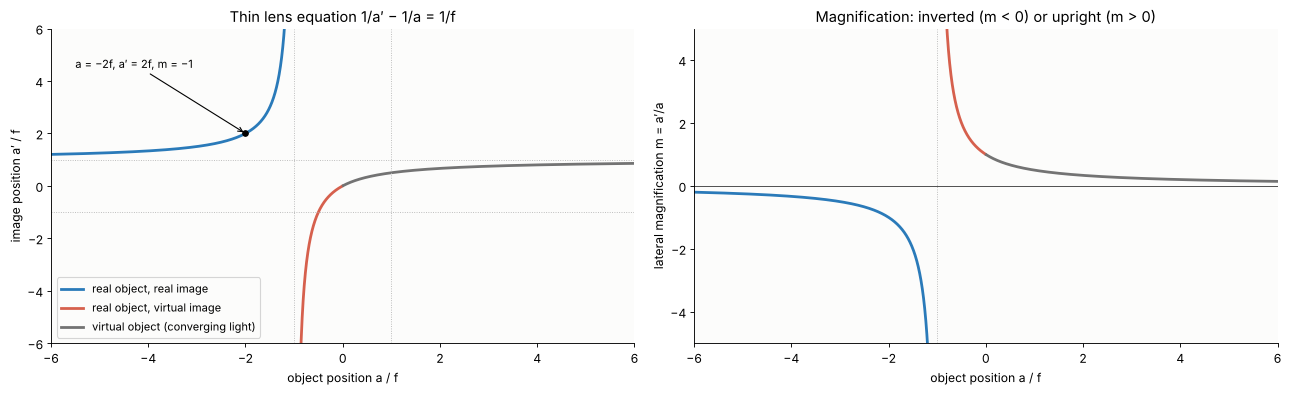

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
a = np.linspace(-6, 6, 4001)*f_demo
a = a[(np.abs(a) > 1) & (np.abs(a + f_demo) > 2)]
a_img = 1/(1/f_demo + 1/a)
m = a_img/a
for sel, col, lab in (((a < -f_demo), BLUE, "real object, real image"),
                      ((a > -f_demo) & (a < 0), RED, "real object, virtual image"),
                      ((a > 0), GREY, "virtual object (converging light)")):
    for part in (sel & (a < -f_demo), sel & (a >= -f_demo)):
        if part.any():
            ax[0].plot(a[part]/f_demo, a_img[part]/f_demo, color=col, lw=2.5, label=lab)
            ax[1].plot(a[part]/f_demo, m[part], color=col, lw=2.5)
            lab = None
for x0, txt in ((-1, "F"), (1, "F′")):
    ax[0].axvline(x0, color="0.7", lw=0.8, ls=":")
    ax[0].axhline(x0, color="0.7", lw=0.8, ls=":")
ax[0].plot([-2], [2], "ko", ms=5)
ax[0].annotate("a = −2f, a′ = 2f, m = −1", (-2, 2), (-5.5, 4.5), fontsize=10, arrowprops=dict(arrowstyle="->"))
ax[0].set_xlim(-6, 6)
ax[0].set_ylim(-6, 6)
ax[0].set_xlabel("object position a / f")
ax[0].set_ylabel("image position a′ / f")
ax[0].set_title("Thin lens equation 1/a′ − 1/a = 1/f")
ax[0].legend(fontsize=10, loc="lower left")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].axvline(-1, color="0.7", lw=0.8, ls=":")
ax[1].set_xlim(-6, 6)
ax[1].set_ylim(-5, 5)
ax[1].set_xlabel("object position a / f")
ax[1].set_ylabel("lateral magnification m = a′/a")
ax[1].set_title("Magnification: inverted (m < 0) or upright (m > 0)")
plt.show()

The equation, the paraxial trace and the real rays through the ideal
lens agree to rounding; all rays from the object point meet in the image
plane within $10^{-15}$ mm. An object at 100.5 mm, just outside $F$,
is imaged 20 m away and 200 times larger, and an object at infinity
(here 100 m) is imaged in the focal plane. The curves above contain the
whole thin lens: as the object approaches the lens from far away, the
image moves out from $F'$ to infinity; for objects inside $F$ the image
jumps to the left side of the lens and becomes **virtual**.

## 3. Real and virtual images

**Real images** are formed where rays from an object point actually
meet. They can be caught on a screen or a sensor. **Virtual images** lie
where the rays only *seem* to come from: the light behind the lens
diverges as if it came from a point in front of it, and only a further
lens, e.g. the eye, can turn it into a real image. Three rays from the
tip of the object suffice to find the image in a drawing, because each
of them is known without calculation:

- the ray **parallel to the axis** (blue) goes through $F'$,
- the ray **through the centre** of the lens (green) goes straight on,
- the ray **through $F$** (orange) leaves parallel to the axis.

For a virtual image the emerging rays are traced back (dashed). For a
diverging lens, $F'$ lies in front of the lens: the parallel ray leaves
as if it came from $F'$, and the ray aimed at $F$ (behind the lens)
leaves parallel.

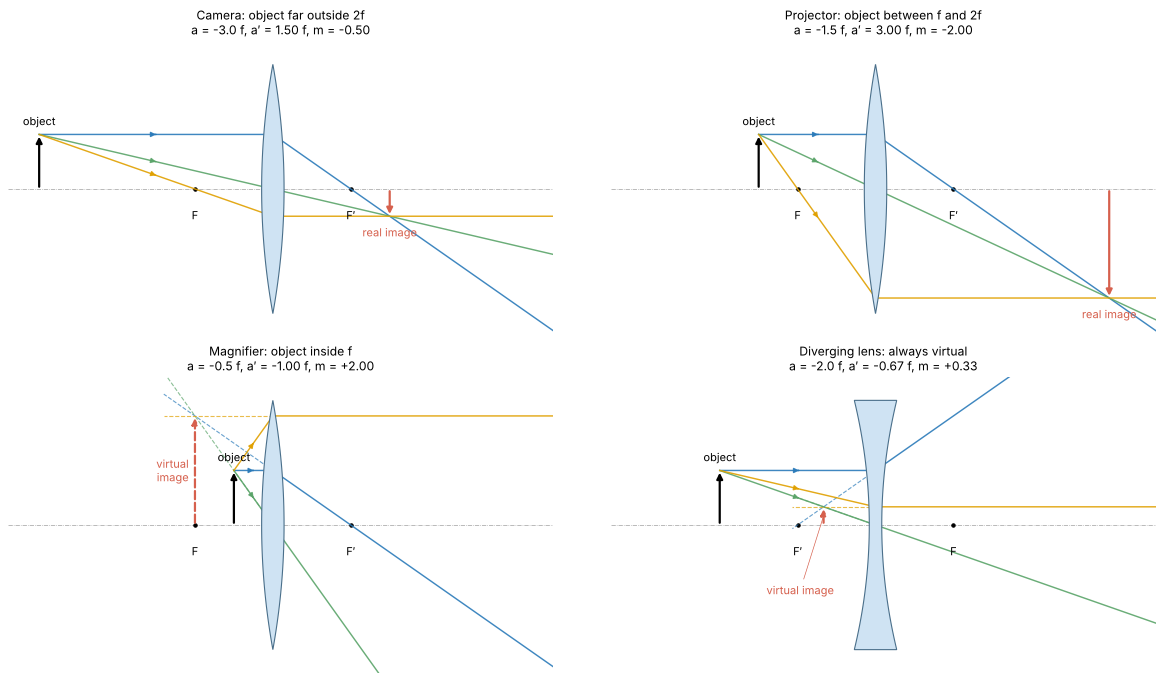

In [6]:
def diverging_lens(ax, z, h, color=sketch.GLASS, edgecolor=sketch.EDGE):
    """Biconcave thin lens symbol."""
    yy = np.linspace(-h, h, 41)
    w = 0.05*h + 0.12*h*(yy/h)**2
    pts = np.r_[np.c_[z + w, yy], np.c_[z - w[::-1], yy[::-1]]]
    ax.add_patch(mpatches.Polygon(pts, closed=True, facecolor=color, edgecolor=edgecolor, lw=1, zorder=3))


def ray_diagram(ax, f, a, h=0.7, z_lim=(-3.4, 3.6), y_lim=(-1.9, 1.9), title=None):
    """Thin lens at z = 0, object arrow of height h at z = a, the three principal rays."""
    a_img = 1/(1/f + 1/a)
    m = a_img/a
    real = a_img > 0
    lenses = [(0.0, f)]
    (sketch.lens if f > 0 else diverging_lens)(ax, 0.0, 1.6)
    ax.axhline(0, color="0.6", lw=0.6, ls="-.")
    for zf, name in ((-f, "F"), (f, "F′")):
        ax.plot([zf], [0], "k.", ms=6)
        ax.text(zf, -0.25, name, ha="center", va="top", fontsize=10)
    ax.annotate("", (a, h), (a, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
    ax.text(a, h + 0.12, "object", ha="center", fontsize=10)
    slopes = (0.0, h/a, -h/(-f - a))       # parallel ray, ray through the centre, ray through (towards) F
    cols = (BLUE, GREEN, ORANGE)
    for u0, col in zip(slopes, cols):
        zs, ys = sketch.draw_ray(ax, lenses, a, h, u0, z_lim[1], color=col, lw=1.3)
        if not real:   # trace the emerging ray back to the virtual image
            u1 = (ys[-1] - ys[-2])/(zs[-1] - zs[-2])
            z_back = a_img - 0.4
            ax.plot([0, z_back], [ys[1], ys[1] + u1*z_back], color=col, lw=1, ls="--", alpha=0.7)
    ax.annotate("", (a_img, m*h), (a_img, 0),
                arrowprops=dict(arrowstyle="-|>", color=RED, lw=2, ls="-" if real else "--"))
    if real:
        ax.text(a_img, m*h - 0.12, "real image", ha="center", va="top", color=RED, fontsize=10)
    elif m > 1:
        ax.text(a_img - 0.08, m*h/2, "virtual\nimage", ha="right", va="center", color=RED, fontsize=10)
    else:
        ax.annotate("virtual image", (a_img, 0.5*m*h), (a_img - 0.3, -0.75), ha="center", va="top", color=RED,
                    fontsize=10, arrowprops=dict(arrowstyle="-", color=RED, lw=0.6))
    ax.set_xlim(*z_lim)
    ax.set_ylim(*y_lim)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title + "\na = {:.1f} f, a′ = {:.2f} f, m = {:+.2f}".format(a/abs(f), a_img/abs(f), m),
                 fontsize=11)


fig, ax = plt.subplots(2, 2, figsize=(15, 8.4), layout="constrained")
ray_diagram(ax[0, 0], 1.0, -3.0, title="Camera: object far outside 2f")
ray_diagram(ax[0, 1], 1.0, -1.5, title="Projector: object between f and 2f")
ray_diagram(ax[1, 0], 1.0, -0.5, title="Magnifier: object inside f")
ray_diagram(ax[1, 1], -1.0, -2.0, title="Diverging lens: always virtual")
plt.show()

The four cases are the four classical uses of a single lens:

| object position | image | orientation and size | used in |
|---|---|---|---|
| $a < -2f$ | real, between $f$ and $2f$ | inverted, reduced | camera, eye |
| $-2f < a < -f$ | real, beyond $2f$ | inverted, magnified | projector, microscope objective |
| $-f < a < 0$ | virtual, in front of the lens | upright, magnified | magnifier, eyepiece |
| any (diverging lens) | virtual, between $F'$ and the lens | upright, reduced | Galilei telescope eyepiece, spectacles for short sight |

A ray tracer has no difficulty with virtual images: we simply place the
image plane at the negative distance that the lens equation gives. The
rays traced through the ideal lens are then extended backwards to that
plane, and all of them again meet in one point:

In [7]:
cases = (("camera", 100.0, -300.0), ("projector", 100.0, -150.0), ("magnifier", 100.0, -50.0),
         ("diverging lens", -100.0, -200.0))
for name, f, a in cases:
    S = rt.System([rt.IdealLens(f, 0.0, semi_diameter=8.0)], 0, lam, object_distance=-a, object_height=5.0)
    S = S.at_paraxial_focus()
    sd = S.spot_diagram(N=15)
    b = S.trace_pupil(5.0, 0.0, np.linspace(-1, 1, 9))
    y_img = b.points[-1][:, 1]
    print("{:15s} image plane at z = {:+8.2f} mm ({}), image height {:+6.2f} mm (m = {:+.3f}), "
          "rays meet within {:.0e} mm".format(name, S.surfaces[-1].thickness,
                                             "real" if S.surfaces[-1].thickness > 0 else "virtual",
                                             y_img.mean(), y_img.mean()/5.0, np.ptp(y_img)))

camera          image plane at z =  +150.00 mm (real), image height  -2.50 mm (m = -0.500), rays meet within 3e-15 mm
projector       image plane at z =  +300.00 mm (real), image height -10.00 mm (m = -2.000), rays meet within 9e-15 mm
magnifier       image plane at z =  -100.00 mm (virtual), image height +10.00 mm (m = +2.000), rays meet within 4e-15 mm
diverging lens  image plane at z =   -66.67 mm (virtual), image height  +1.67 mm (m = +0.333), rays meet within 2e-15 mm


The ray tracer finds the virtual images as easily as the real ones, at
the same positions and with the same magnifications as the drawings.

## 4. Thick lenses and principal planes

A real lens has a thickness $t$, and the thin lens equation no longer
holds with $a$ and $a'$ measured from the lens: from which of its two
surfaces should they be measured? Gauss's answer is that every
rotationally symmetric system, however many surfaces it has, behaves
paraxially like a thin lens if the distances are measured from two
special planes, the **principal planes** $H$ (object side) and $H'$
(image side). They are conjugate with the magnification $+1$: a ray
that enters aimed at a height $y$ on $H$ leaves as if it came from the
same height $y$ on $H'$. In between, the system acts like a thin lens
whose two halves are pulled apart. The **effective focal length** $f'$
is the distance from $H'$ to $F'$. For a single thick lens in air,

$$\frac{1}{f} = (n - 1)\left[\frac{1}{R_1} - \frac{1}{R_2} + \frac{(n - 1)\,t}{n R_1 R_2}\right],\qquad
z_H = -\frac{f (n - 1)\,t}{n R_2},\qquad z_{H'} - t = -\frac{f (n - 1)\,t}{n R_1},$$

with $z_H$ measured from the first and $z_{H'} - t$ from the second
vertex. The distance from the last vertex to $F'$ is the **back focal
length**, the one that can be measured with a ruler. A biconvex lens
12 mm thick:

In [8]:
def bk7_lens(R1, R2, t, D=30.0):
    return [rt.Surface(R1, t, n_after=n_bk7, semi_diameter=D/2), rt.Surface(R2, 0.0, n_after=1.0, semi_diameter=D/2)]


def thick_lens_formulas(R1, R2, t, n=n_bk7):
    """Focal length and principal planes (from the first and the second vertex)."""
    c1, c2 = 1/R1, 1/R2
    phi = (n - 1)*(c1 - c2 + (n - 1)*t*c1*c2/n)
    f = 1/phi
    return f, -f*(n - 1)*t*c2/n, -f*(n - 1)*t*c1/n


R1, R2, t = 60.0, -60.0, 12.0
thick = rt.System(bk7_lens(R1, R2, t), 0, lam)
cp = thick.paraxial().cardinal_points
f_t, zH, zH2 = thick_lens_formulas(R1, R2, t)
print("biconvex R = +-60 mm, 12 mm thick: f = {:.3f} mm (formula) / {:.3f} mm (trace)".format(f_t, cp.f_prime))
print("  H  at z = {:.3f} mm (formula) / {:.3f} mm (trace), H' at z = {:.3f} mm / {:.3f} mm"
      .format(zH, cp.H, t + zH2, cp.H_prime))
print("  thin lens with the same radii: f = {:.3f} mm".format(1/((n_bk7 - 1)*(2/60.0))))

# the thin lens equation holds from the principal planes:
for s_obj in (400.0, 200.0, 150.0):
    S = rt.System(bk7_lens(R1, R2, t), 0, lam, object_distance=s_obj, object_height=1.0)
    p = S.paraxial()
    a = -(s_obj + cp.H)                         # object position measured from H
    a_img_pred = 1/(1/cp.f_prime + 1/a)          # image position measured from H'
    a_img = t + p.image_distance - cp.H_prime
    print("object {:5.0f} mm in front of the lens: a' from H' = {:8.3f} mm (thin lens eq.) / {:8.3f} mm "
          "(trace), m = {:+.4f} / {:+.4f}".format(s_obj, a_img_pred, a_img, a_img_pred/a, p.magnification))

biconvex R = +-60 mm, 12 mm thick: f = 60.097 mm (formula) / 60.097 mm (trace)
  H  at z = 4.095 mm (formula) / 4.095 mm (trace), H' at z = 7.905 mm / 7.905 mm
  thin lens with the same radii: f = 58.050 mm
object   400 mm in front of the lens: a' from H' =   70.596 mm (thin lens eq.) /   70.596 mm (trace), m = -0.1747 / -0.1747
object   200 mm in front of the lens: a' from H' =   85.179 mm (thin lens eq.) /   85.179 mm (trace), m = -0.4173 / -0.4173
object   150 mm in front of the lens: a' from H' =   98.520 mm (thin lens eq.) /   98.520 mm (trace), m = -0.6393 / -0.6393


The formulas and the trace agree, and with $a$ measured from $H$ and $a'$
from $H'$ the thin lens equation holds exactly for the thick lens. The
thickness changes the focal length from 58.05 mm (the lensmaker's
equation) to 60.10 mm, and the principal planes of the symmetric lens
sit inside it, near a third of the thickness from either vertex.

Bending a lens moves its principal planes. Below, four BK7 lenses with
the same focal length of 100 mm and 8 mm thickness are bent from
biconvex to meniscus; on the right is a **telephoto** pair: a
converging lens followed by a diverging one. For the top ray, the
incoming line and the emerging ray are extended (red dashes); they meet
on $H'$:

biconvex                           H at    +2.67 mm, H' at    +5.33 mm, F' at  105.33 mm from the first vertex, F' - H' = 100.00 mm
plano-convex, convex side first    H at    -0.00 mm, H' at    +2.73 mm, F' at  102.73 mm from the first vertex, F' - H' = 100.00 mm
plano-convex, flat side first      H at    +5.27 mm, H' at    +8.00 mm, F' at  108.00 mm from the first vertex, F' - H' = 100.00 mm
positive meniscus                  H at    -4.81 mm, H' at    -1.62 mm, F' at   98.38 mm from the first vertex, F' - H' = 100.00 mm
telephoto pair                     H at  -300.00 mm, H' at  -120.00 mm, F' at  180.00 mm from the first vertex, F' - H' = 300.00 mm


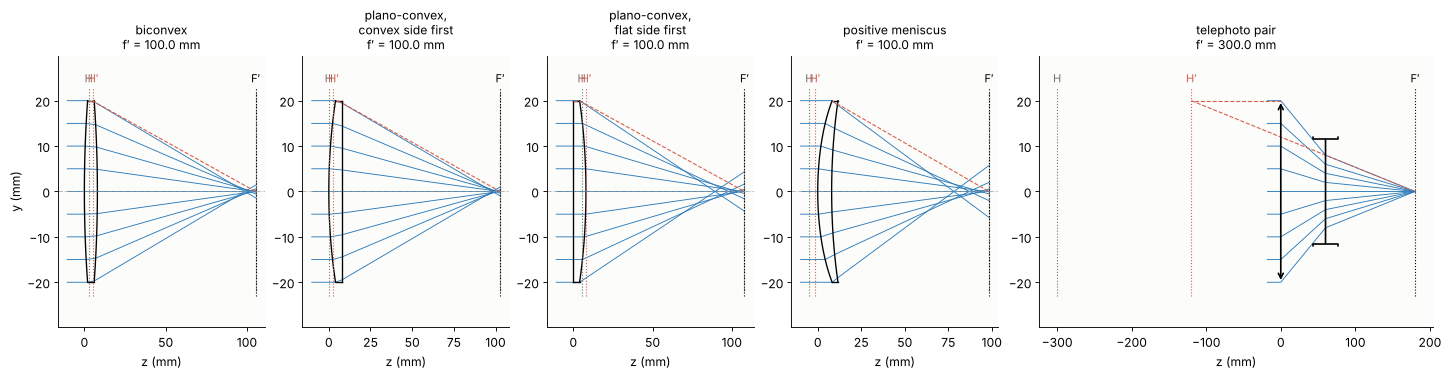

In [9]:
X_shapes = {"biconvex": 0.0, "plano-convex,\nconvex side first": 1.0, "plano-convex,\nflat side first": -1.0,
            "positive meniscus": 3.0}


def bent(X, f=100.0, t=8.0, D=40.0):
    dc = 1/(f*(n_bk7 - 1))
    c1, c2 = dc*(X + 1)/2, dc*(X - 1)/2
    R = [np.inf if c == 0 else 1/c for c in (c1, c2)]
    # rescale the curvatures slightly so that the thick lens has f = 100 mm exactly
    k = brentq(lambda k: rt.System(bk7_lens(R[0]/k, R[1]/k, t, D), 0, lam).paraxial().efl - f, 0.8, 1.2)
    return rt.System(bk7_lens(R[0]/k, R[1]/k, t, D), 0, lam).at_paraxial_focus()


tele = rt.System([rt.IdealLens(100.0, 60.0, semi_diameter=20.0), rt.IdealLens(-60.0, 0.0, semi_diameter=12.0)],
                 0, lam).at_paraxial_focus()

fig, ax = plt.subplots(1, 5, figsize=(18, 4.6), layout="constrained", width_ratios=[1, 1, 1, 1, 1.9])
for a_, (name, X) in zip(ax, list(X_shapes.items()) + [("telephoto pair", None)]):
    S = tele if X is None else bent(X)
    p = S.paraxial()
    cpX = p.cardinal_points
    h_in = np.array([0.5])
    b = S.trace_pupil(0.0, 0.0, np.linspace(-1, 1, 9))
    pts = b.points
    a_.plot(pts[:, :, 2], pts[:, :, 1], color=BLUE, lw=0.8)
    for i, s in enumerate(S.surfaces):
        if isinstance(s, rt.IdealLens):
            a_.annotate("", (S.vertex_z[i], s.semi_diameter), (S.vertex_z[i], -s.semi_diameter),
                        arrowprops=dict(arrowstyle="<->" if s.f > 0 else "]-[", color="k", lw=1.5))
    if X is not None:
        S.draw(a_, n_rays=2, colors=["none"])
    # extend the top ray: incoming line and outgoing line meet on H'
    j = 8
    y0 = pts[0, j, 1]
    z_last, y_last = pts[-2, j, 2], pts[-2, j, 1]
    dz, dy = b.directions[-2][j, 2], b.directions[-2][j, 1]
    z_meet = z_last + (y0 - y_last)*dz/dy
    a_.plot([pts[1, j, 2], z_meet], [y0, y0], color=RED, lw=1, ls="--")
    a_.plot([z_meet, pts[-1, j, 2]], [y0, 0], color=RED, lw=1, ls="--")
    ymax = 1.15*np.nanmax(np.abs(pts[:, :, 1]))
    for zz, lab, col in ((cpX.H, "H", GREY), (cpX.H_prime, "H′", RED), (cpX.F_prime, "F′", "k")):
        a_.plot([zz, zz], [-ymax, ymax], color=col, lw=1, ls=":")
        a_.text(zz, ymax*1.02, lab, color=col, ha="center", va="bottom", fontsize=10)
    a_.set_title(name + "\nf′ = {:.1f} mm".format(cpX.f_prime), fontsize=11)
    a_.set_xlabel("z (mm)")
    a_.set_aspect("auto")
    a_.set_ylim(-1.3*ymax, 1.3*ymax)
    a_.set_ylabel("")
    print("{:34s} H at {:+8.2f} mm, H' at {:+8.2f} mm, F' at {:7.2f} mm from the first vertex, F' - H' = {:.2f} mm"
          .format(name.replace("\n", " "), cpX.H, cpX.H_prime, cpX.F_prime, cpX.F_prime - cpX.H_prime))
ax[0].set_ylabel("y (mm)")
plt.show()

One principal plane of a plano-convex lens touches the vertex of its
curved surface and the other lies inside the glass; those of a meniscus
leave the glass on its convex side. The focal length is always measured
from $H'$, the back focal length from the glass. For the telephoto pair, $H'$ lies 120 mm in
front of the first lens. The pair has a focal length of 300 mm but is
only 180 mm from the first lens to the focus: this is how long focal
length camera lenses are made short.

The construction with $H'$ is paraxial. If we extend real rays at
larger heights in the same way, the meeting points leave the plane
(left below), and the rays no longer pass through $F'$ (right, the
spherical aberration of section 1 again, now for the whole lens). The
meeting points lie on a curved **principal surface**. For a lens that
satisfies Abbe's **sine condition** (notebook 102, sine and Herschel conditions), the principal
surface is a sphere of radius $f'$ around $F'$ (dashed); such a lens is
free of coma. The plano-convex lens with its convex side towards the
parallel light comes close; turned round, its principal surface bends
the wrong way and its spherical aberration is four times larger. Which
way round a lens goes matters, and section 7 explains why.

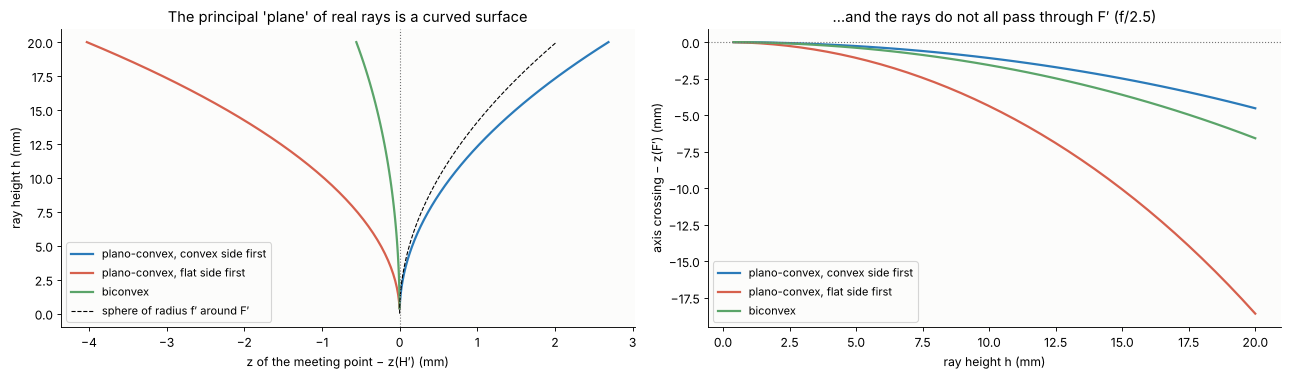

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained")
for (name, X), col in zip((("plano-convex, convex side first", 1.0), ("plano-convex, flat side first", -1.0),
                           ("biconvex", 0.0)), (BLUE, RED, GREEN)):
    S = bent(X, D=40.0)
    cpX = S.paraxial().cardinal_points
    py = np.linspace(0.02, 1, 40)
    b = S.trace_pupil(0.0, 0.0, py)
    y0 = b.points[0][:, 1]
    zl, yl = b.points[-2][:, 2], b.points[-2][:, 1]
    dz, dy = b.directions[-2][:, 2], b.directions[-2][:, 1]
    z_meet = zl + (y0 - yl)*dz/dy
    z_axis = zl - yl*dz/dy
    ax[0].plot(z_meet - cpX.H_prime, y0, "-", color=col, lw=2, label=name)
    ax[1].plot(y0, z_axis - cpX.F_prime, "-", color=col, lw=2, label=name)
yy = np.linspace(0, 20, 100)
ax[0].plot(100.0 - np.sqrt(100.0**2 - yy**2), yy, "k--", lw=1, label="sphere of radius f′ around F′")
ax[0].axvline(0, color=GREY, lw=1, ls=":")
ax[0].set_xlabel("z of the meeting point − z(H′) (mm)")
ax[0].set_ylabel("ray height h (mm)")
ax[0].set_title("The principal 'plane' of real rays is a curved surface")
ax[0].legend(fontsize=10)
ax[1].axhline(0, color=GREY, lw=1, ls=":")
ax[1].set_xlabel("ray height h (mm)")
ax[1].set_ylabel("axis crossing − z(F′) (mm)")
ax[1].set_title("…and the rays do not all pass through F′ (f/2.5)")
ax[1].legend(fontsize=10)
plt.show()

## 5. Stops, pupils, f-number and numerical aperture

So far the lenses had no edge. Real systems limit the bundles of rays
with apertures. The one that limits the cone of rays from an axial
object point is the **aperture stop**; it sets the brightness of the
image and, as we will see, its sharpness. Its image in the parts of the
system in front of it is the **entrance pupil**, its image in the parts
behind it the **exit pupil**. Two rays describe a system:

- the **marginal ray** goes from the axial object point to the rim of
  the stop (and of both pupils),
- the **chief ray** goes from the edge of the field through the centre
  of the stop (and of both pupils).

The marginal ray fixes the image position (where it crosses the axis)
and the aperture, the chief ray the image height (where it crosses the
image plane). A second aperture, the **field stop**, limits the size of
the field that is imaged; it sits in an image plane, e.g. the frame of
a sensor or the diaphragm in a microscope eyepiece.

The aperture is quoted as the **f-number** $N = f'/D$ (focal length over
entrance pupil diameter, for objects at infinity) or as the **numerical
aperture** $\mathrm{NA} = n'\sin U'$ (the sine of the half angle of the
cone of rays at the image, times the index there). Paraxially
$\mathrm{NA} = 1/(2N)$. The diffraction limit of a lens depends only on
these numbers (section 8). Example: a stop 25 mm in front of the
plano-convex lens (flat side first, the classical "landscape lens" of
box cameras):

stop 25 mm in front of the lens, radius 5 mm: entrance pupil at z = 0.00 mm, radius 5.00 mm
exit pupil at z = -10.42 mm, radius 7.17 mm (the image of the stop in the lens)
f-number f'/D = 10.00, image space NA = n' sin U' ~ 0.0500 ~ 1/(2N) = 0.0500


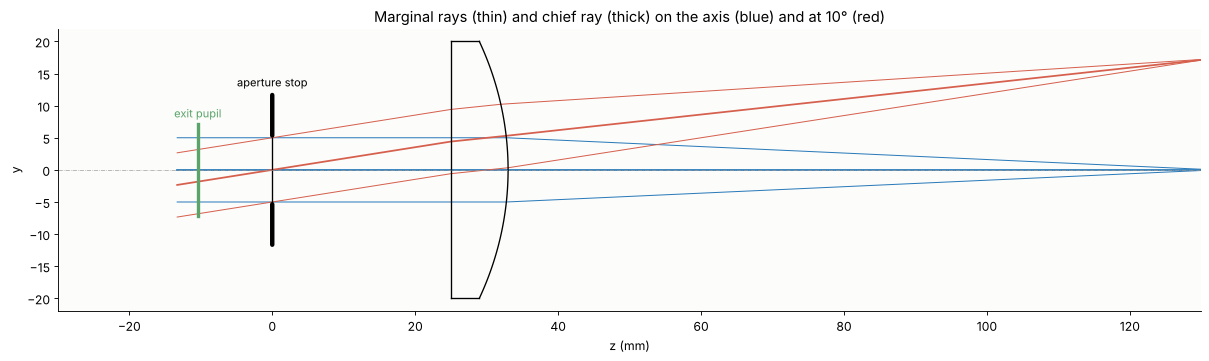

In [11]:
stop_dist = 25.0
landscape = rt.System([rt.Surface(np.inf, stop_dist, semi_diameter=5.0)] + bent(-1.0).surfaces[:2],
                      0, lam, field_angle=np.radians(10)).at_paraxial_focus()
pl = landscape.paraxial()
print("stop 25 mm in front of the lens, radius 5 mm: entrance pupil at z = {:.2f} mm, radius {:.2f} mm"
      .format(pl.ep_z, pl.ep_radius))
print("exit pupil at z = {:.2f} mm, radius {:.2f} mm (the image of the stop in the lens)".format(pl.xp_z, pl.xp_radius))
print("f-number f'/D = {:.2f}, image space NA = n' sin U' ~ {:.4f} ~ 1/(2N) = {:.4f}"
      .format(pl.f_number, pl.na, 1/(2*pl.f_number)))

fig, ax = plt.subplots(figsize=(15, 4.4), layout="constrained")
for fld, col in ((0.0, BLUE), (np.radians(10), RED)):
    b = landscape.trace_pupil(fld, 0.0, np.array([-1, 0, 1.0]))
    for j, ls in zip(range(3), ("-", "-", "-")):
        ax.plot(b.points[:, j, 2], b.points[:, j, 1], color=col, lw=1.6 if j == 1 else 0.9)
landscape.draw(ax, fields=[0.0], n_rays=2, colors=["none"])
ax.annotate("", (0, 5), (0, 12), arrowprops=dict(arrowstyle="-", color="k", lw=4))
ax.annotate("", (0, -5), (0, -12), arrowprops=dict(arrowstyle="-", color="k", lw=4))
ax.text(0, 13, "aperture stop", ha="center", fontsize=10)
ax.plot([pl.xp_z]*2, [-pl.xp_radius, pl.xp_radius], color=GREEN, lw=3)
ax.text(pl.xp_z, pl.xp_radius + 1, "exit pupil", ha="center", color=GREEN, fontsize=10)
ax.set_xlim(-30, 130)
ax.set_aspect("auto")
ax.set_title("Marginal rays (thin) and chief ray (thick) on the axis (blue) and at 10° (red)")
ax.set_xlabel("z (mm)")
plt.show()

With nothing in front of the stop, the entrance pupil is the stop itself.
The exit pupil, the image of the stop in the lens, is virtual: it lies
10.4 mm to the left of the stop, 35 mm in front of the lens, and the
emerging chief ray at 10° seems to come from its centre. The aperture is
$f/10$, $\mathrm{NA} = 0.05$.

## 6. Simple optical instruments

The eye forms real images on its retina. Its focal length (about 17 mm
in air for a relaxed eye) is fixed by its size, so the only way to see
more detail is to bring the object closer, which makes it subtend a
larger angle. The eye cannot focus closer than its **near point**,
conventionally 250 mm (the *conventional visual distance*). An object of
height $y$ there subtends the angle $y/250$ mm. Optical instruments are
judged by how much they enlarge the angle under which the eye sees the
object, their **angular magnification** or *magnifying power*

$$M = \frac{\text{angle with the instrument}}{\text{angle seen with the naked eye}}.$$

What matters on the retina is this angle: the retinal image is the angle
times the eye's focal length, regardless of how the eye focuses. We
model the eye as a pupil of 3 mm diameter and let the ray tracer find
the chief ray that passes its centre.

### The magnifier

A converging lens with the object just inside its focal point makes an
upright virtual image (section 3) far away; the eye sees the object
under the angle $y/f$ instead of $y/250$ mm. If the object is in $F$
(the image at infinity, relaxed eye), $M = 250\,\text{mm}/f$; if the
image is at the near point and the eye close to the lens,
$M = 1 + 250\,\text{mm}/f$:

In [12]:
f_eye, near_point, r_eye = 17.0, 250.0, 1.5      # reduced eye in air, near point, eye pupil radius (mm)


def apparent_angle(instrument, eye_distance, object_distance, object_height=1.0):
    """Paraxial angle (slope) under which the eye, a stop of radius r_eye eye_distance behind the
    last element of `instrument`, sees the object: the slope of the chief ray entering the eye."""
    surfaces = list(instrument)
    surfaces[-1] = rt.IdealLens(surfaces[-1].f, eye_distance, semi_diameter=surfaces[-1].semi_diameter)
    eye = rt.Surface(np.inf, f_eye, semi_diameter=r_eye, label="eye pupil")
    S = rt.System(surfaces + [eye], len(surfaces), lam, object_distance=object_distance,
                  object_height=object_height)
    with np.errstate(divide="ignore"):              # the f-number is infinite for a relaxed eye
        return S.paraxial().chief[-1, 1]


naked = 1.0/near_point
print("naked eye: a 1 mm object at the near point appears under {:.4f} rad".format(naked))
f_mag = 50.0
for name, s_obj in (("relaxed eye, object in F", f_mag),
                    ("image at the near point", 1/(1/f_mag + 1/near_point))):
    M = -apparent_angle([rt.IdealLens(f_mag, 0.0, semi_diameter=15.0)], 0.0, s_obj)/naked
    print("magnifier f = 50 mm, {:24s}: object {:6.2f} mm in front, M = {:.3f} (250/f = {:.1f}, 1 + 250/f = {:.1f})"
          .format(name, s_obj, M, near_point/f_mag, 1 + near_point/f_mag))

naked eye: a 1 mm object at the near point appears under 0.0040 rad
magnifier f = 50 mm, relaxed eye, object in F: object  50.00 mm in front, M = 5.000 (250/f = 5.0, 1 + 250/f = 6.0)
magnifier f = 50 mm, image at the near point : object  41.67 mm in front, M = 6.000 (250/f = 5.0, 1 + 250/f = 6.0)


Both values are reproduced exactly. A magnifier is limited to about
$M \approx 10$: a stronger lens has a short focal length and a small
diameter and becomes impractical.

### The compound microscope

The microscope does it in two steps. The **objective**, a short focal
length lens, makes a real, inverted and magnified image (the projector
case of section 3). The **eyepiece** is a magnifier for that
intermediate image. The intermediate image lies at the **optical tube
length** $L$ behind the back focal point of the objective (160 mm in the
classical standard), so the objective magnifies by $m_\text{obj} = -L/f_\text{obj}$
and the whole microscope by

$$M = m_\text{obj}\,M_\text{ep} = -\frac{L}{f_\text{obj}}\cdot\frac{250\ \text{mm}}{f_\text{ep}}.$$

A 10× objective ($f = 16$ mm) and a 10× eyepiece ($f = 25$ mm) give
100×. The objective is the aperture stop, and the exit pupil, its image
through the eyepiece, is the **eye point**, where the observer's pupil
has to be:

In [13]:
f_obj, L_tube, f_ep = 16.0, 160.0, 25.0
a_img_obj = f_obj + L_tube                       # intermediate image behind the objective
s_obj = -1/(1/a_img_obj - 1/f_obj)               # object distance in front of the objective
scope = [rt.IdealLens(f_obj, a_img_obj + f_ep, semi_diameter=4.0), rt.IdealLens(f_ep, 0.0, semi_diameter=10.0)]
pm = rt.System(scope, 0, lam, object_distance=s_obj, object_height=0.1).paraxial()
eye_relief = pm.xp_z - (a_img_obj + f_ep)
print("objective f = {:.0f} mm: object {:.2f} mm in front, intermediate image {:.0f} mm behind it, m_obj = {:.2f}"
      .format(f_obj, s_obj, a_img_obj, -L_tube/f_obj))
print("exit pupil (eye point) {:.2f} mm behind the eyepiece, diameter {:.2f} mm".format(eye_relief, 2*pm.xp_radius))
# the eye at the exit pupil; the objective stays the aperture stop:
M_scope = -rt.System(scope[:1] + [rt.IdealLens(f_ep, eye_relief, semi_diameter=10.0)], 0, lam,
                     object_distance=s_obj, object_height=1.0).paraxial().chief[-1, 1]/naked
print("microscope: M = {:.2f}, -(L/f_obj)(250/f_ep) = {:.2f}".format(M_scope, -(L_tube/f_obj)*(near_point/f_ep)))
microscope = rt.System(scope[:1] + [rt.IdealLens(f_ep, eye_relief, semi_diameter=4.0),
                                    rt.IdealLens(f_eye, f_eye, semi_diameter=r_eye)], 0, lam,
                       object_distance=s_obj, object_height=0.25)

objective f = 16 mm: object 17.60 mm in front, intermediate image 176 mm behind it, m_obj = -10.00
exit pupil (eye point) 28.55 mm behind the eyepiece, diameter 1.14 mm
microscope: M = -100.00, -(L/f_obj)(250/f_ep) = -100.00


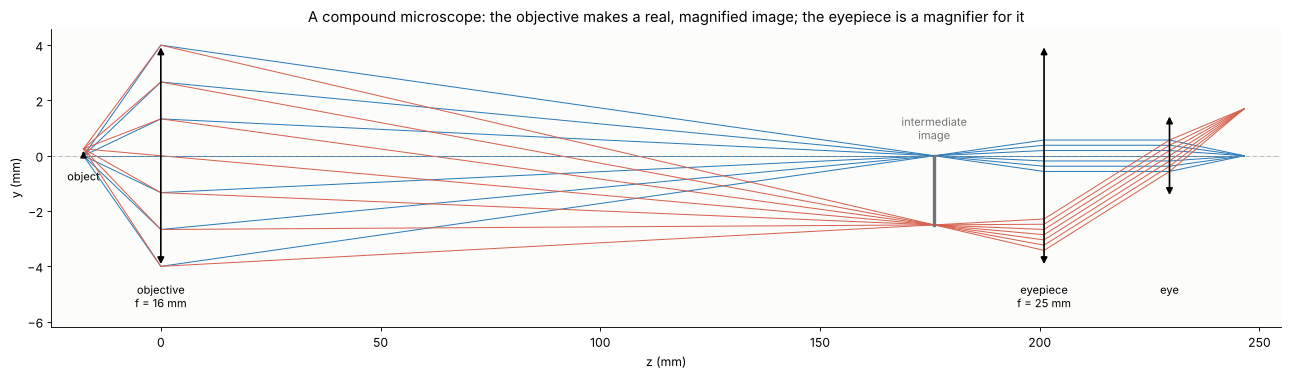

In [14]:
def draw_thin_system(ax, S, fields, colors, n_rays=5, labels=None, label_y=None):
    """Rays through a system of ideal lenses (y axis stretched)."""
    for fld, col in zip(fields, colors):
        b = S.trace_pupil(fld, 0.0, np.linspace(-1, 1, n_rays))
        ax.plot(b.points[:, :, 2], b.points[:, :, 1], color=col, lw=0.9)
    for i, s in enumerate(S.surfaces):
        if isinstance(s, rt.IdealLens):
            h = s.semi_diameter
            ax.annotate("", (S.vertex_z[i], h), (S.vertex_z[i], -h),
                        arrowprops=dict(arrowstyle="<|-|>" if s.f > 0 else "]-[", color="k", lw=1.5,
                                        mutation_scale=12))
            if labels:
                ax.text(S.vertex_z[i], -h*1.12 if label_y is None else label_y, labels[i], ha="center",
                        va="top", fontsize=10)
    ax.axhline(0, color="0.6", lw=0.6, ls="-.")
    ax.set_xlabel("z (mm)")


fig, ax = plt.subplots(figsize=(16, 4.6), layout="constrained")
draw_thin_system(ax, microscope, [0.0, 0.25], [BLUE, RED], n_rays=7,
                 labels=["objective\nf = 16 mm", "eyepiece\nf = 25 mm", "eye"], label_y=-4.6)
ax.annotate("", (-s_obj, 0.25), (-s_obj, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
ax.plot([a_img_obj]*2, [0, -L_tube/f_obj*0.25], color=GREY, lw=3)
ax.text(a_img_obj, 0.6, "intermediate\nimage", ha="center", fontsize=10, color=GREY)
ax.text(-s_obj, -0.5, "object", ha="center", va="top", fontsize=10)
ax.set_xlim(-25, 255)
ax.set_ylim(-6.2, 4.6)
ax.set_ylabel("y (mm)")
ax.set_title("A compound microscope: the objective makes a real, magnified image; the eyepiece is a magnifier for it")
plt.show()

The microscope magnifies $-100\times$ (the minus sign: the image is
inverted), as the formula says, and its exit pupil lies 28.6 mm behind
the eyepiece with a diameter of 1.1 mm, smaller than the eye's pupil, so
all the light collected by the objective enters the eye. The field stop
of the eyepiece sits in the plane of the intermediate image, where it
is seen sharply as the edge of the field of view. (How fine a detail a
microscope can resolve is not a question of magnification but of
diffraction and the NA of the objective, see notebook 52, Abbe image formation.)

### The telescope

A telescope looks at objects at infinity and sends their light into the
eye as parallel light again: it is an **afocal** system, with no focal
length (its ABCD matrix has $C = 0$). The objective of focal length
$f_o$ makes a real image of the sky in its focal plane, and the
eyepiece, placed one focal length $f_e$ behind it, turns every point of
it into a parallel beam. The angles are magnified by

$$M = -\frac{f_o}{f_e}.$$

With a converging eyepiece (**Kepler**, $f_e > 0$, length $f_o + f_e$)
the image is inverted, which astronomers accept. With a diverging
eyepiece placed before the focus (**Galilei**, $f_e < 0$, length
$f_o - |f_e|$) it is upright: the opera glass. The exit pupil of a
Kepler telescope is a real image of the objective behind the eyepiece
(the *Ramsden disc*), of diameter $D/|M|$; binoculars are labelled e.g.
8×40, and 40 mm/8 = 5 mm is their exit pupil, made to fill the pupil
of the dark adapted eye. A Galilei telescope has a virtual exit pupil
inside the tube, which the eye cannot reach; this limits its field of
view.

In [15]:
f_o, D_o = 500.0, 50.0
theta = np.radians(0.5)
naked_inf = rt.System([rt.IdealLens(f_eye, f_eye, semi_diameter=r_eye)], 0, lam, field_angle=theta).paraxial().image_height
telescopes = {}
for name, f_e in (("Kepler", 25.0), ("Galilei", -25.0)):
    tube = [rt.IdealLens(f_o, f_o + f_e, semi_diameter=D_o/2), rt.IdealLens(f_e, 30.0, semi_diameter=8.0)]
    T = rt.System(tube, 0, lam, field_angle=theta)
    M = T.abcd_matrix()
    pt = T.paraxial()
    relief = pt.xp_z - (f_o + f_e)
    eye_at = relief if relief > 0 else 10.0
    T_eye = rt.System(tube[:1] + [rt.IdealLens(f_e, eye_at, semi_diameter=8.0),
                                  rt.IdealLens(f_eye, f_eye, semi_diameter=r_eye)], 0, lam, field_angle=theta)
    telescopes[name] = T_eye
    b = T.trace_pupil(theta, 0.0, 0.0)
    ang_out = np.arctan(b.directions[-1][0, 1]/b.directions[-1][0, 2])
    print("{:8s}: f_o = {} mm, f_e = {:+} mm, length {:.0f} mm; system matrix C = {:.1e} (afocal)"
          .format(name, f_o, f_e, f_o + f_e, M[1, 0]))
    print("          angular magnification: chief ray {:+.3f}, retinal image {:+.3f}, -f_o/f_e = {:+.1f}"
          .format(np.tan(ang_out)/np.tan(theta), T_eye.paraxial().image_height/naked_inf, -f_o/f_e))
    print("          exit pupil {:+.1f} mm behind the eyepiece ({}), diameter {:.2f} mm = D/|M| = {:.2f} mm"
          .format(relief, "eye relief" if relief > 0 else "virtual, inside the tube", 2*pt.xp_radius,
                  D_o/abs(f_o/f_e)))

Kepler  : f_o = 500.0 mm, f_e = +25.0 mm, length 525 mm; system matrix C = 8.7e-19 (afocal)
          angular magnification: chief ray -20.000, retinal image -20.000, -f_o/f_e = -20.0
          exit pupil +26.2 mm behind the eyepiece (eye relief), diameter 2.50 mm = D/|M| = 2.50 mm
Galilei : f_o = 500.0 mm, f_e = -25.0 mm, length 475 mm; system matrix C = -8.7e-19 (afocal)
          angular magnification: chief ray +20.000, retinal image +20.000, -f_o/f_e = +20.0
          exit pupil -23.8 mm behind the eyepiece (virtual, inside the tube), diameter 2.50 mm = D/|M| = 2.50 mm


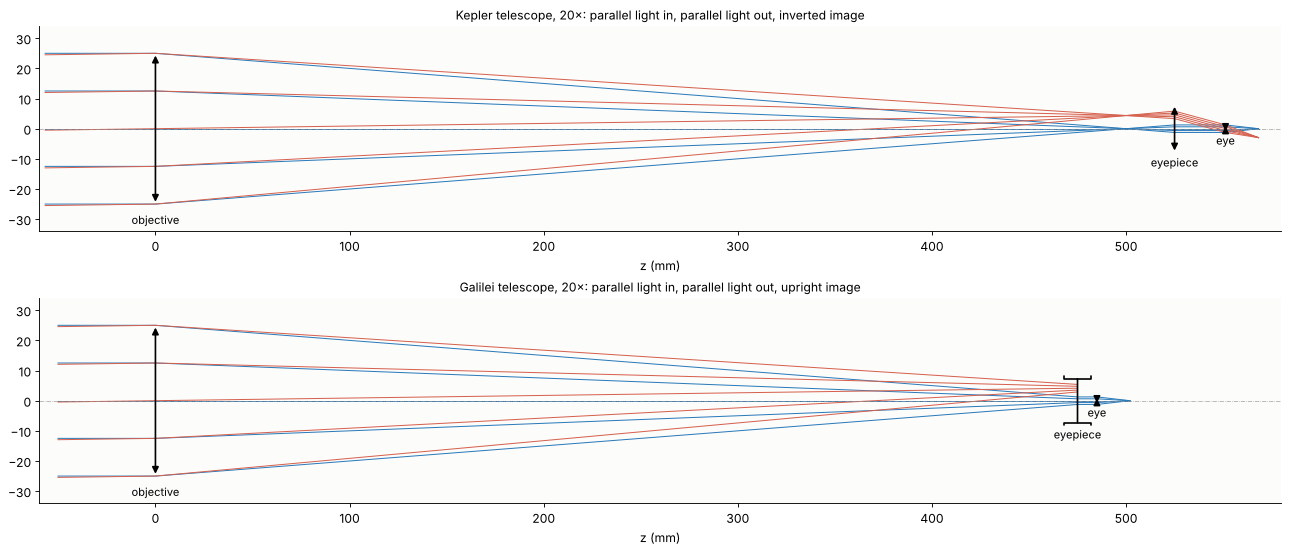

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(16, 6.8), layout="constrained")
for a_, (name, T_eye) in zip(ax, telescopes.items()):
    draw_thin_system(a_, T_eye, [0.0, np.radians(0.5)], [BLUE, RED], n_rays=5,
                     labels=["objective", "eyepiece", "eye"])
    a_.set_xlim(-60, 580)
    a_.set_ylim(-34, 34)
    a_.set_title("{} telescope, 20×: parallel light in, parallel light out, {} image".format(
        name, "inverted" if name == "Kepler" else "upright"), fontsize=11)
plt.show()

Both telescopes are afocal to rounding ($C \approx 10^{-18}$/mm), and the
chief ray and the retinal image of the eye both give $M = \mp 20$. The
Kepler telescope has an eye relief of 26 mm and an exit pupil of 2.5 mm
= 50 mm/20; the exit pupil of the Galilei telescope is a virtual image
23.8 mm in front of the eyepiece. In the drawing of the Galilei
telescope the rays of the field point (red) pass the eye's pupil
off centre; a larger field would miss it.

## 7. Aberrations and the Seidel sums

Real lenses are not ideal. Sections 1 and 4 showed spherical aberration,
the dependence of the focus on the ray height. A complete description
uses the **wavefront**: an ideal lens turns the light of an object
point into a spherical wave converging to the image point, and a real
lens produces a deformed wave. The deviation, measured as an optical
path along the rays, is the **wavefront aberration** or **optical path
difference** $W$ (OPD). It is a function of the position in the
pupil, given by the normalized radius $\rho$ and the angle $\theta$
(measured from the direction towards the field point, $y$), and of the
normalized field height $H$. For a rotationally symmetric system,
symmetry allows only combinations of $H^2$, $\rho^2$ and
$H\rho\cos\theta$, and the lowest order terms beyond focus and tilt are
the five **Seidel aberrations** (Ludwig von Seidel, 1856):

$$W = W_{040}\,\rho^4 + W_{131}\,H\rho^3\cos\theta + W_{222}\,H^2\rho^2\cos^2\theta
+ W_{220}\,H^2\rho^2 + W_{311}\,H^3\rho\cos\theta.$$

They are called third order aberrations because the ray errors that they
cause are of third order in the ray height and the field. Each has a
characteristic shape over the pupil:

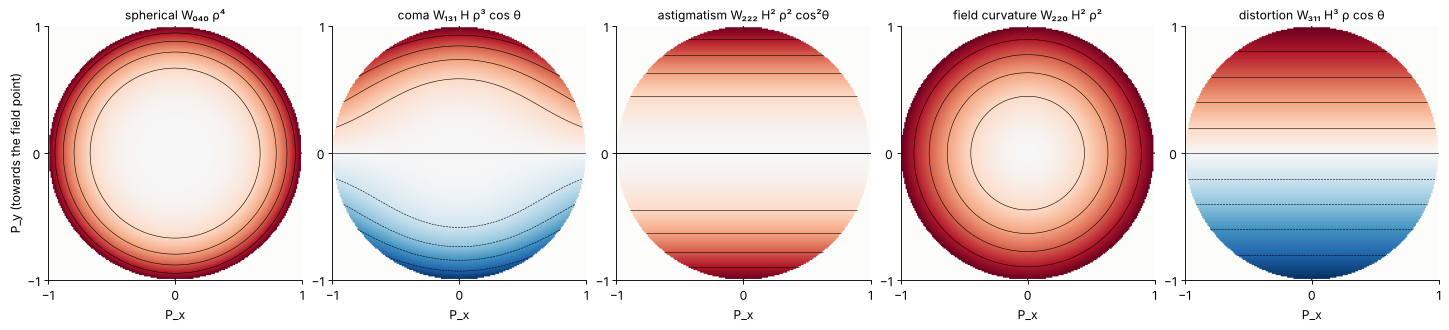

In [17]:
rho_g = np.linspace(-1, 1, 201)
PXg, PYg = np.meshgrid(rho_g, rho_g)
R2g = PXg**2 + PYg**2
inside = R2g <= 1
terms = {"spherical W₀₄₀ ρ⁴": R2g**2, "coma W₁₃₁ H ρ³ cos θ": R2g*PYg, "astigmatism W₂₂₂ H² ρ² cos²θ": PYg**2,
         "field curvature W₂₂₀ H² ρ²": R2g, "distortion W₃₁₁ H³ ρ cos θ": PYg}
fig, ax = plt.subplots(1, 5, figsize=(18, 3.9), layout="constrained")
for a_, (name, W) in zip(ax, terms.items()):
    a_.imshow(np.where(inside, W, np.nan), extent=(-1, 1, -1, 1), origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
    a_.contour(rho_g, rho_g, np.where(inside, W, np.nan), levels=np.linspace(-1, 1, 11), colors="k",
               linewidths=0.5)
    a_.set_title(name, fontsize=11)
    a_.set_xlabel("P_x")
    a_.set_xticks([-1, 0, 1])
    a_.set_yticks([-1, 0, 1])
ax[0].set_ylabel("P_y (towards the field point)")
plt.show()

- **spherical aberration** ($\rho^4$): the outer zones of the pupil focus
  at a different distance, the same at every field point;
- **coma** ($H\rho^3\cos\theta$): the zones of the pupil image a field
  point with different magnifications, which smears it into a comet;
- **astigmatism** ($H^2\rho^2\cos^2\theta$): the tangential (meridional)
  and the sagittal fans of rays focus at different distances;
- **field curvature** ($H^2\rho^2$): the image of a flat object lies on
  a curved surface (the Petzval surface, if there is no astigmatism);
- **distortion** ($H^3\rho\cos\theta$): a pure tilt of the wavefront
  that grows with $H^3$; the image is sharp but at the wrong height
  (barrel or pincushion).

The coefficients follow from the paraxial marginal and chief rays alone,
surface by surface: these are the **Seidel sums** $S_I$ to $S_V$, with
$W_{040} = -S_I/8$, $W_{131} = -S_{II}/2$, $W_{222} = -S_{III}/2$,
$W_{220} = -(S_{III} + S_{IV})/4$ and $W_{311} = -S_V/2$ (Welford;
pyoptics' OPD is negative for a lens whose rim rays focus too short,
which Welford counts positive). Every surface contributes, and the sum
is what the image sees. `System.seidel()` evaluates them. We check them
against the traced OPD of a BK7 singlet of 100 mm focal length at f/8
and 3° field, by fitting the Seidel polynomials (plus higher orders) to
the map of real rays:

In [18]:
def singlet(X, f=100.0, D=25.0, t=5.0, field=np.radians(3.0), stop_dist=None, n=n_bk7):
    """BK7 singlet of shape factor X = (c1 + c2)/(c1 - c2), object at infinity, image at the paraxial focus."""
    dc = 1/(f*(n - 1))
    c1, c2 = dc*(X + 1)/2, dc*(X - 1)/2
    R = [np.inf if c == 0 else 1/c for c in (c1, c2)]
    s = [rt.Surface(R[0], t, n_after=n, semi_diameter=D/2 + 3), rt.Surface(R[1], 0.0, n_after=1.0, semi_diameter=D/2 + 3)]
    if stop_dist is not None:
        s = [rt.Surface(np.inf, stop_dist, semi_diameter=D/2, label="stop")] + s
    return rt.System(s, 0, lam, field_angle=field, entrance_pupil_radius=D/2).at_paraxial_focus()


def seidel_fit(S, field=None):
    """Fit W040, W131, W222, W220 (waves) to the traced OPD map (pupil coordinates, field along y)."""
    m = S.opd(field, N=64)
    PX, PY = np.meshgrid(m.px, m.py)
    ok = np.isfinite(m.W)
    r2 = PX**2 + PY**2
    cols = [np.ones_like(PX), PY, r2, PY**2, r2*PY, r2**2, r2**3, r2**2*PY, r2*PY**2]
    A = np.column_stack([c[ok] for c in cols])
    co = np.linalg.lstsq(A, m.W[ok], rcond=None)[0]
    return co[5], co[4], co[3], co[2]


S8 = singlet(0.7, D=12.5)
sd8 = S8.seidel()
fit8 = seidel_fit(S8)
print("best form singlet f = 100 mm at f/8, field 3 deg (waves at 587.6 nm):")
for name, w_s, w_f in zip(("W040", "W131", "W222", "W220"), (sd8.W040, sd8.W131, sd8.W222, sd8.W220), fit8):
    print("   {}: Seidel sum {:+.4f}, fitted to traced rays {:+.4f}".format(name, w_s, w_f))
to = S8.third_order()
print("Petzval radius {:.2f} mm (thin lens: -n f = {:.2f} mm); tangential image surface {:.1f} mm, sagittal {:.1f} mm"
      .format(to.petzval_radius, -n_bk7*100, to.tangential_radius, to.sagittal_radius))

best form singlet f = 100 mm at f/8, field 3 deg (waves at 587.6 nm):
   W040: Seidel sum -0.6471, fitted to traced rays -0.6490
   W131: Seidel sum +0.1731, fitted to traced rays +0.1722
   W222: Seidel sum -0.8771, fitted to traced rays -0.8735
   W220: Seidel sum -0.7395, fitted to traced rays -0.7382
Petzval radius -151.68 mm (thin lens: -n f = -151.68 mm); tangential image surface -28.2 mm, sagittal -61.7 mm


Third order theory and real rays agree within 0.5 % at f/8: the
Seidel sums *are* the aberrations of the lens as long as the aperture
and the field are moderate. The field curvature contains the
**Petzval sum** $\sum \phi_k/n_k$, which depends only on the powers and
indices of the lenses, not on their shapes. For a thin singlet the
Petzval surface has the radius $-n f$ (= $-151.7$ mm here, curved
towards the lens); astigmatism bends the tangential image surface
further (radius $-28$ mm) than the sagittal one ($-62$ mm). No bending
of a single positive lens can flatten its field; that takes negative
lenses (as in the Cooke triplet) or, in notebook 44 (Seidel aberrations), whole groups.

### Bending a lens

A singlet of fixed focal length can still be bent. The **shape factor**
$X = (c_1 + c_2)/(c_1 - c_2)$, with the curvatures $c = 1/R$, is $0$ for a
symmetric biconvex lens and $\pm 1$ for plano-convex lenses with the
convex side first ($+1$) or last ($-1$). For an object at infinity,
the spherical aberration of a thin lens is a parabola in $X$ (Welford,
section 7.4):

$$S_I = \frac{y^4\phi^3}{4}\left[\left(\frac{n}{n - 1}\right)^2 + \frac{n + 2}{n(n - 1)^2}X^2
- \frac{4(n + 1)}{n(n - 1)}X + \frac{3n + 2}{n}\right],$$

with the marginal ray height $y$ and the power $\phi = 1/f$. It is
smallest for $X = 2(n^2 - 1)/(n + 2)$, i.e. 0.74 for BK7: a lens that is
almost, but not quite, plano-convex with its convex side towards the
parallel light. It cannot be made zero: a positive singlet with
spherical surfaces always has spherical aberration of the same sign
(*undercorrected*), and correcting it takes a second lens (a cemented
doublet) or an asphere. We compare the formula with the Seidel sums of
the 5 mm thick lens and with real rays, at f/4:

In [19]:
def welford_W040(X, f=100.0, D=25.0, n=n_bk7):
    """Spherical aberration of a thin lens for an object at infinity (Welford's form with C = -1)."""
    y, K, C = D/2, 1/f, -1.0
    S_I = y**4*K**3/4*((n/(n - 1))**2 + (n + 2)/(n*(n - 1)**2)*X**2
                       + 4*(n + 1)/(n*(n - 1))*X*C + (3*n + 2)/n*C**2)
    return -S_I/8/lam


Xs = np.linspace(-2, 3, 26)
w040_thin, w040_seidel, w040_traced, w131_seidel = [], [], [], []
for X in Xs:
    S = singlet(X, t=5.0)
    sd = S.seidel()
    w040_seidel.append(sd.W040)
    w131_seidel.append(sd.W131)
    w040_traced.append(seidel_fit(S, 0.0)[0])
    w040_thin.append(welford_W040(X))
w040_thin, w040_seidel, w040_traced, w131_seidel = map(np.array, (w040_thin, w040_seidel, w040_traced, w131_seidel))
X_best = -2*(n_bk7**2 - 1)*(-1.0)/(n_bk7 + 2)
X_coma = brentq(lambda X: singlet(X).seidel().W131, 0.0, 2.0)
print("thin lens theory: least spherical aberration at X = {:.3f}; 5 mm thick lens (Seidel): X = {:.2f}"
      .format(X_best, Xs[np.argmax(w040_seidel)]))
print("coma vanishes at X = {:.2f} (stop at the lens)".format(X_coma))
for X in (-1.0, 1.0):
    k = np.argmin(np.abs(Xs - X))
    print("plano-convex, {}: W040 = {:.2f} waves".format("flat side first" if X < 0 else "convex side first", w040_seidel[k]))

thin lens theory: least spherical aberration at X = 0.740; 5 mm thick lens (Seidel): X = 0.80
coma vanishes at X = 0.81 (stop at the lens)
plano-convex, flat side first: W040 = -44.74 waves
plano-convex, convex side first: W040 = -11.29 waves


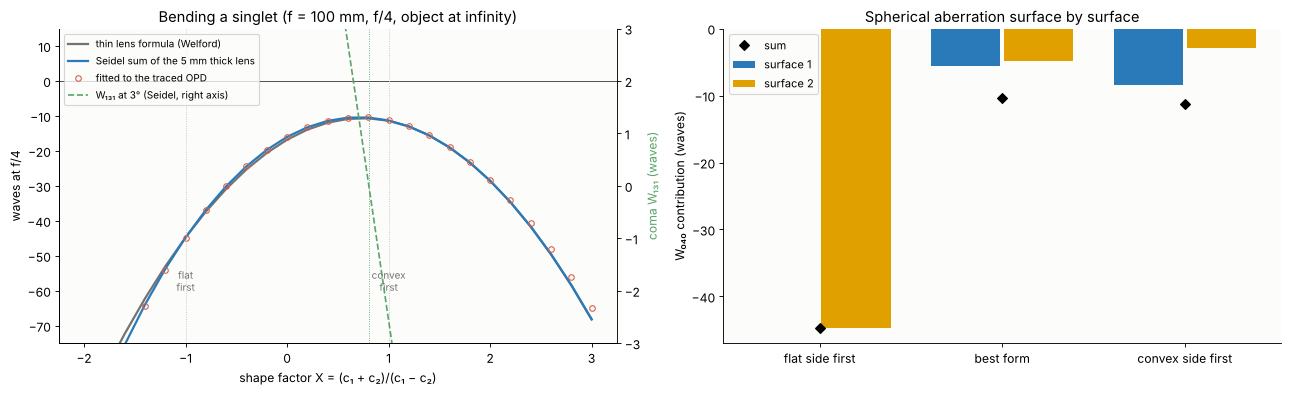

W040 per surface (waves): [[ -0.   -44.74]
 [ -5.56  -4.8 ]
 [ -8.45  -2.84]]


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
ax[0].plot(Xs, w040_thin, "-", color=GREY, lw=2, label="thin lens formula (Welford)")
ax[0].plot(Xs, w040_seidel, "-", color=BLUE, lw=2, label="Seidel sum of the 5 mm thick lens")
ax[0].plot(Xs, w040_traced, "o", color=RED, ms=5, mfc="none", label="fitted to the traced OPD")
ax[0].axhline(0, color="k", lw=0.6)
for X, txt in ((-1, "flat\nfirst"), (1, "convex\nfirst")):
    ax[0].axvline(X, color="0.75", lw=0.8, ls=":")
    ax[0].text(X, -60, txt, ha="center", fontsize=9, color=GREY)
ax[0].set_xlabel("shape factor X = (c₁ + c₂)/(c₁ − c₂)")
ax[0].set_ylabel("waves at f/4")
ax[0].set_title("Bending a singlet (f = 100 mm, f/4, object at infinity)")
ax[0].set_ylim(-75, 15)
axc = ax[0].twinx()
axc.spines["right"].set_visible(True)
axc.plot(Xs, w131_seidel, "--", color=GREEN, lw=1.5, label="W₁₃₁ at 3° (Seidel, right axis)")
axc.axvline(X_coma, color=GREEN, lw=0.8, ls=":")
axc.set_ylim(-3, 3)
axc.set_ylabel("coma W₁₃₁ (waves)", color=GREEN)
h0, l0 = ax[0].get_legend_handles_labels()
h1, l1 = axc.get_legend_handles_labels()
ax[0].legend(h0 + h1, l0 + l1, fontsize=9, loc="upper left")

# who contributes: the two surfaces of the two plano-convex orientations and of the best form
names = ("flat side first", "best form", "convex side first")
wsurf = np.array([singlet(X).seidel().W[:, 0] for X in (-1.0, X_best, 1.0)])
xx = np.arange(3)
ax[1].bar(xx - 0.2, wsurf[:, 0], 0.38, color=BLUE, label="surface 1")
ax[1].bar(xx + 0.2, wsurf[:, 1], 0.38, color=ORANGE, label="surface 2")
ax[1].plot(xx, wsurf.sum(1), "kD", ms=7, label="sum")
ax[1].set_xticks(xx, names)
ax[1].set_ylabel("W₀₄₀ contribution (waves)")
ax[1].set_title("Spherical aberration surface by surface")
ax[1].legend(fontsize=10)
plt.show()
print("W040 per surface (waves):", np.round(wsurf, 2))

The thin lens formula, the Seidel sums of the thick lens and the traced
rays lie on the same parabola, apart from higher order aberration at
strong bendings. The best form, $X = 0.80$ for the thick lens, has
10.4 waves of spherical aberration at f/4; the plano-convex lens has
11.3 waves the right way round and 44.7 waves the wrong way round, four
times as much. The bar chart shows why. With the flat side towards the
parallel light, the first surface does nothing and the second one has to
bend the rays alone, at large angles of incidence. With the convex side
first the two surfaces share the work. Spherical aberration grows with
the third power of the angles (Snell's law, section 1), so two small
refractions are better than one large one. This is the rule for every
lens design: split the bending of the rays over many surfaces. And
coma, with the stop at the lens, vanishes at $X = 0.81$, close to the
best form: the right way round a singlet is good for both (notebook 102, sine and Herschel conditions).

### Moving the stop

The Seidel sums also depend on where the stop is, because the chief
ray passes the lens elsewhere. Moving the stop leaves the spherical
aberration and the Petzval sum unchanged (they do not involve the chief
ray), changes the coma linearly with the shift, the astigmatism
quadratically and the distortion cubically (the **stop shift
equations**). The best form singlet at f/8 with a 10° field:

stop    0 mm in front: W040 -0.648, W131 +0.364, W222 -9.957, W220 -8.385 waves, distortion -0.05 %
stop   20 mm in front: W040 -0.648, W131 -1.098, W222 -10.372, W220 -8.592 waves, distortion -1.16 %
stop   40 mm in front: W040 -0.648, W131 -2.560, W222 -12.436, W220 -9.625 waves, distortion -2.38 %
stop   60 mm in front: W040 -0.648, W131 -4.022, W222 -16.150, W220 -11.482 waves, distortion -3.86 %
coma-free stop position: 5.0 mm in front of the lens


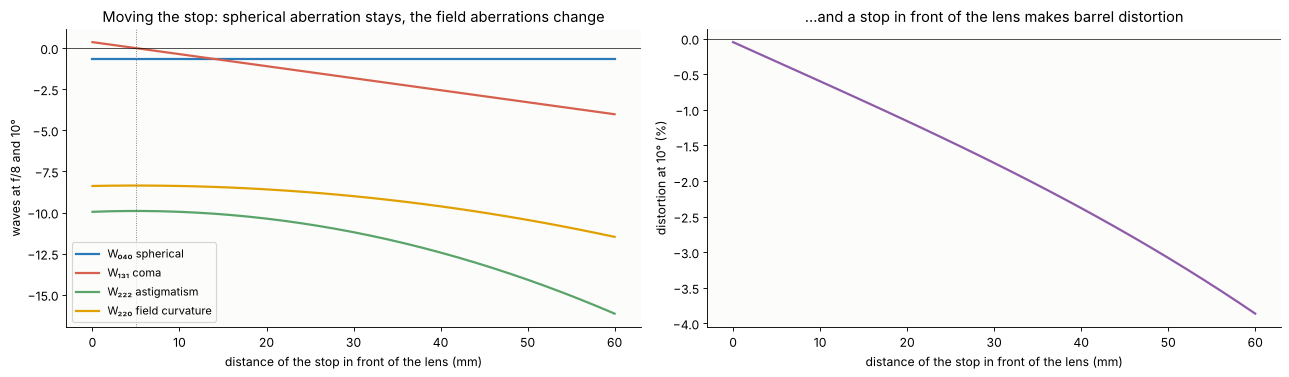

In [21]:
X_c = X_best
stops = np.linspace(-0.0, 60.0, 31)
stop_rows = []
for sdist in stops:
    S = singlet(X_c, D=12.5, field=np.radians(10.0), stop_dist=sdist if sdist > 0 else None)
    sd = S.seidel()
    stop_rows.append((sd.W040, sd.W131, sd.W222, sd.W220, 100*S.third_order().distortion))
stop_rows = np.array(stop_rows)
for k in (0, 10, 20, 30):
    print("stop {:4.0f} mm in front: W040 {:+.3f}, W131 {:+.3f}, W222 {:+.3f}, W220 {:+.3f} waves, distortion {:+.2f} %"
          .format(stops[k], *stop_rows[k]))
s_free = np.interp(0, stop_rows[::-1, 1], stops[::-1])
print("coma-free stop position: {:.1f} mm in front of the lens".format(s_free))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained")
for j, (lab, col) in enumerate(zip(("W₀₄₀ spherical", "W₁₃₁ coma", "W₂₂₂ astigmatism", "W₂₂₀ field curvature"),
                                   (BLUE, RED, GREEN, ORANGE))):
    ax[0].plot(stops, stop_rows[:, j], color=col, lw=2, label=lab)
ax[0].axhline(0, color="k", lw=0.6)
ax[0].axvline(s_free, color=GREY, lw=0.8, ls=":")
ax[0].set_xlabel("distance of the stop in front of the lens (mm)")
ax[0].set_ylabel("waves at f/8 and 10°")
ax[0].set_title("Moving the stop: spherical aberration stays, the field aberrations change")
ax[0].legend(fontsize=10)
ax[1].plot(stops, stop_rows[:, 4], color=PURPLE, lw=2)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_xlabel("distance of the stop in front of the lens (mm)")
ax[1].set_ylabel("distortion at 10° (%)")
ax[1].set_title("…and a stop in front of the lens makes barrel distortion")
plt.show()

The spherical aberration stays at $-0.65$ waves wherever the stop is,
while the coma passes through zero with the stop 5 mm in front of the
lens. There the astigmatism has its extremum: the stop shift equations
couple the two. A stop in front of a positive lens makes *barrel*
distortion (behind it would make *pincushion*), $-3.9$ % with the stop
60 mm in front. Symmetric lenses with the stop in the middle (most
camera lenses) cancel coma and distortion between their two halves.

## 8. Wavefront error and image quality

How large may an aberration be? Wave optics gives the answer: the image
of a point is the diffraction pattern of the pupil (notebook 17, PSF, MTF and Strehl), and
an aberration only matters if it changes that pattern. Two numbers
summarize the OPD map over the pupil: the **peak to valley** (PV) and
the **rms** value (the standard deviation of $W$ over the pupil area).
Both depend on the reference sphere, i.e. on the image plane: moving
the image plane by $\delta z$ adds the defocus term
$W_{020}\rho^2$ with $W_{020} \approx -\mathrm{NA}'^2\delta z/2$ (in
length units), which can be used to **balance** the spherical
aberration. For $W = W_{040}(\rho^4 - \rho^2)$ the rms error drops from
$|W_{040}|/\sqrt{5.625}$ at the paraxial focus to $|W_{040}|/\sqrt{180}$,
four times less. The best form singlet at f/4 on the axis:

best form singlet at f/4, on axis: W040 = -10.36 waves
  paraxial focus: PV 10.59 waves, rms 3.120 waves (pure W040 rho^4: rms = |W040|/sqrt(5.625) = 3.090)
  best focus 0.787 mm closer to the lens: PV 2.74 waves, rms 0.789 waves (W040 rho^4 - W040 rho^2: 0.773)
  defocus that balances it: W020 = -W040 -> dz = 2 W040 lambda / NA'^2 ~ 0.785 mm


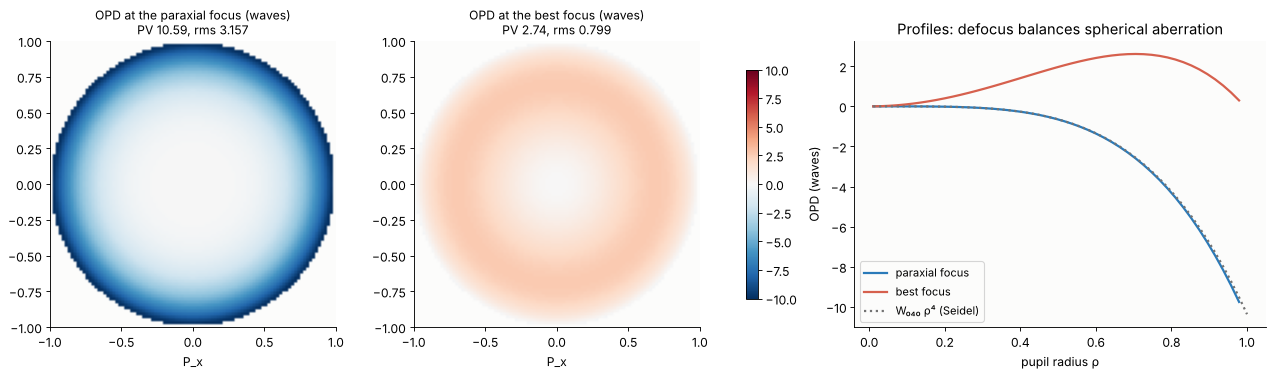

In [22]:
def best_focus(S, field=None):
    """Image plane with the smallest rms wavefront error."""
    z0 = S.surfaces[-1].thickness
    res = minimize_scalar(lambda dz: S.with_image_distance(z0 + dz).rms_opd(field, N=48),
                          bounds=(-3.0, 1.0), method="bounded", options={"xatol": 1e-5})
    return S.with_image_distance(z0 + res.x), res.x


S4 = singlet(X_best, D=25.0)
W040_4 = S4.seidel().W040
m4 = S4.opd(0.0, N=96)
rms_par, pv_par = S4.rms_opd(0.0), np.nanmax(m4.W) - np.nanmin(m4.W)
S4b, dz4 = best_focus(S4, 0.0)
m4b = S4b.opd(0.0, N=96)
rms_best, pv_best = S4b.rms_opd(0.0), np.nanmax(m4b.W) - np.nanmin(m4b.W)
print("best form singlet at f/4, on axis: W040 = {:.2f} waves".format(W040_4))
print("  paraxial focus: PV {:.2f} waves, rms {:.3f} waves (pure W040 rho^4: rms = |W040|/sqrt(5.625) = {:.3f})"
      .format(pv_par, rms_par, abs(W040_4)*np.sqrt(4/45)))
print("  best focus {:.3f} mm closer to the lens: PV {:.2f} waves, rms {:.3f} waves (W040 rho^4 - W040 rho^2: {:.3f})"
      .format(-dz4, pv_best, rms_best, abs(W040_4)/np.sqrt(180)))
print("  defocus that balances it: W020 = -W040 -> dz = 2 W040 lambda / NA'^2 ~ {:.3f} mm"
      .format(-2*W040_4*lam/S4.paraxial().na**2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained", width_ratios=[1, 1, 1.25])
for a_, mm, title in ((ax[0], m4, "paraxial focus"), (ax[1], m4b, "best focus")):
    im = a_.imshow(mm.W, extent=(-1, 1, -1, 1), origin="lower", cmap="RdBu_r", vmin=-10, vmax=10)
    a_.set_title("OPD at the {} (waves)\nPV {:.2f}, rms {:.3f}".format(title, np.nanmax(mm.W) - np.nanmin(mm.W),
                                                                        np.sqrt(np.nanmean((mm.W - np.nanmean(mm.W))**2))),
                 fontsize=11)
    a_.set_xlabel("P_x")
fig.colorbar(im, ax=ax[:2], shrink=0.8)
c = 48
r = m4.px[c:]
ax[2].plot(r, m4.W[c, c:] - m4.W[c, c], color=BLUE, lw=2, label="paraxial focus")
ax[2].plot(r, m4b.W[c, c:] - m4b.W[c, c], color=RED, lw=2, label="best focus")
ax[2].plot(r, W040_4*r**4, ":", color=GREY, lw=2, label="W₀₄₀ ρ⁴ (Seidel)")
ax[2].set_xlabel("pupil radius ρ")
ax[2].set_ylabel("OPD (waves)")
ax[2].set_title("Profiles: defocus balances spherical aberration")
ax[2].legend(fontsize=10)
plt.show()

The paraxial focus has 10.6 waves PV and 3.1 waves rms, as $\rho^4$
predicts. Moving the image plane 0.79 mm towards the lens (the
predicted $2W_{040}\lambda/\mathrm{NA}'^2 = 0.785$ mm) brings the rms
down to 0.79 waves, by the predicted factor of four; the profile
becomes the familiar "M" of balanced spherical aberration.

The **Strehl ratio** $S$ is the peak intensity of the aberrated point
image relative to the aberration-free one. For small aberrations it
depends only on the rms wavefront error $\sigma$ (in waves), the
**Maréchal approximation**

$$S \approx \exp\left[-(2\pi\sigma)^2\right].$$

A system is called **diffraction limited** if $S \ge 0.8$, i.e.
$\sigma \le \lambda/14$ (Maréchal's criterion). Rayleigh's older
**quarter wave rule**, PV $\le \lambda/4$, says nearly the same for
defocus or spherical aberration. Stopping down a lens reduces its
aberrations quickly: $W_{040}$ falls with the fourth power of the
aperture, and the geometrical blur with its third power, while the
diffraction blur, the Airy disk of radius $1.22\,\lambda N$, *grows* in
proportion to the f-number $N$. Somewhere the two cross. The same singlet
stopped down from f/4 to f/16, each time at its best focus:

In [23]:
f_numbers = np.array([4, 5, 6, 7, 8, 10, 12, 16])
rows = []
for N in f_numbers:
    S, _ = best_focus(singlet(X_best, D=100.0/N), 0.0)
    rows.append((S.rms_opd(0.0, N=96), S.strehl(0.0, N=96), S.spot_diagram(0.0, N=41).rms, S))
rms_N = np.array([r_[0] for r_ in rows])
strehl_N = np.array([r_[1] for r_ in rows])
spot_N = np.array([r_[2] for r_ in rows])
airy_N = 1.22*lam*f_numbers
for N, rr, st, sp, ai in zip(f_numbers, rms_N, strehl_N, spot_N, airy_N):
    print("f/{:<3d} rms {:.3f} waves, Strehl {:.3f} (Marechal {:.3f}), rms spot radius {:6.1f} um, Airy radius {:5.1f} um"
          .format(N, rr, st, np.exp(-(2*np.pi*rr)**2), sp*1e3, ai*1e3))
N_dl = np.interp(np.log(1/14), np.log(rms_N[::-1]), f_numbers[::-1])
print("diffraction limited (rms = lambda/14, Strehl 0.8) from about f/{:.1f}".format(N_dl))

f/4   rms 0.799 waves, Strehl 0.044 (Marechal 0.000), rms spot radius   42.0 um, Airy radius   2.9 um
f/5   rms 0.323 waves, Strehl 0.104 (Marechal 0.016), rms spot radius   21.2 um, Airy radius   3.6 um
f/6   rms 0.155 waves, Strehl 0.366 (Marechal 0.388), rms spot radius   12.2 um, Airy radius   4.3 um
f/7   rms 0.083 waves, Strehl 0.757 (Marechal 0.761), rms spot radius    7.6 um, Airy radius   5.0 um
f/8   rms 0.049 waves, Strehl 0.910 (Marechal 0.911), rms spot radius    5.1 um, Airy radius   5.7 um
f/10  rms 0.020 waves, Strehl 0.985 (Marechal 0.985), rms spot radius    2.6 um, Airy radius   7.2 um
f/12  rms 0.010 waves, Strehl 0.996 (Marechal 0.996), rms spot radius    1.5 um, Airy radius   8.6 um
f/16  rms 0.003 waves, Strehl 1.000 (Marechal 1.000), rms spot radius    0.6 um, Airy radius  11.5 um
diffraction limited (rms = lambda/14, Strehl 0.8) from about f/7.3


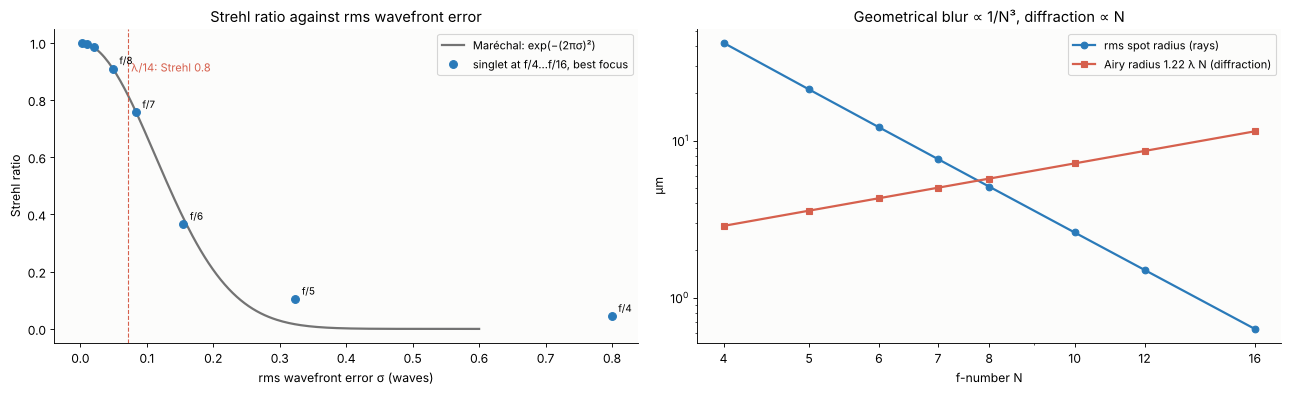

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
ss = np.linspace(0, 0.6, 200)
ax[0].plot(ss, np.exp(-(2*np.pi*ss)**2), color=GREY, lw=2, label="Maréchal: exp(−(2πσ)²)")
ax[0].plot(rms_N, strehl_N, "o", color=BLUE, ms=7, label="singlet at f/4…f/16, best focus")
for N, x_, y_ in zip(f_numbers[:5], rms_N[:5], strehl_N[:5]):
    ax[0].annotate("f/{}".format(N), (x_, y_), (6, 4), textcoords="offset points", fontsize=9)
ax[0].axvline(1/14, color=RED, lw=1, ls="--")
ax[0].text(1/14 + 0.005, 0.9, "λ/14: Strehl 0.8", color=RED, fontsize=10)
ax[0].set_xlabel("rms wavefront error σ (waves)")
ax[0].set_ylabel("Strehl ratio")
ax[0].set_title("Strehl ratio against rms wavefront error")
ax[0].legend(fontsize=10)
ax[1].loglog(f_numbers, spot_N*1e3, "o-", color=BLUE, lw=2, label="rms spot radius (rays)")
ax[1].loglog(f_numbers, airy_N*1e3, "s-", color=RED, lw=2, label="Airy radius 1.22 λ N (diffraction)")
ax[1].set_xlabel("f-number N")
ax[1].set_ylabel("µm")
ax[1].set_xticks(f_numbers, [str(n) for n in f_numbers])
ax[1].set_title("Geometrical blur ∝ 1/N³, diffraction ∝ N")
ax[1].legend(fontsize=10)
plt.show()

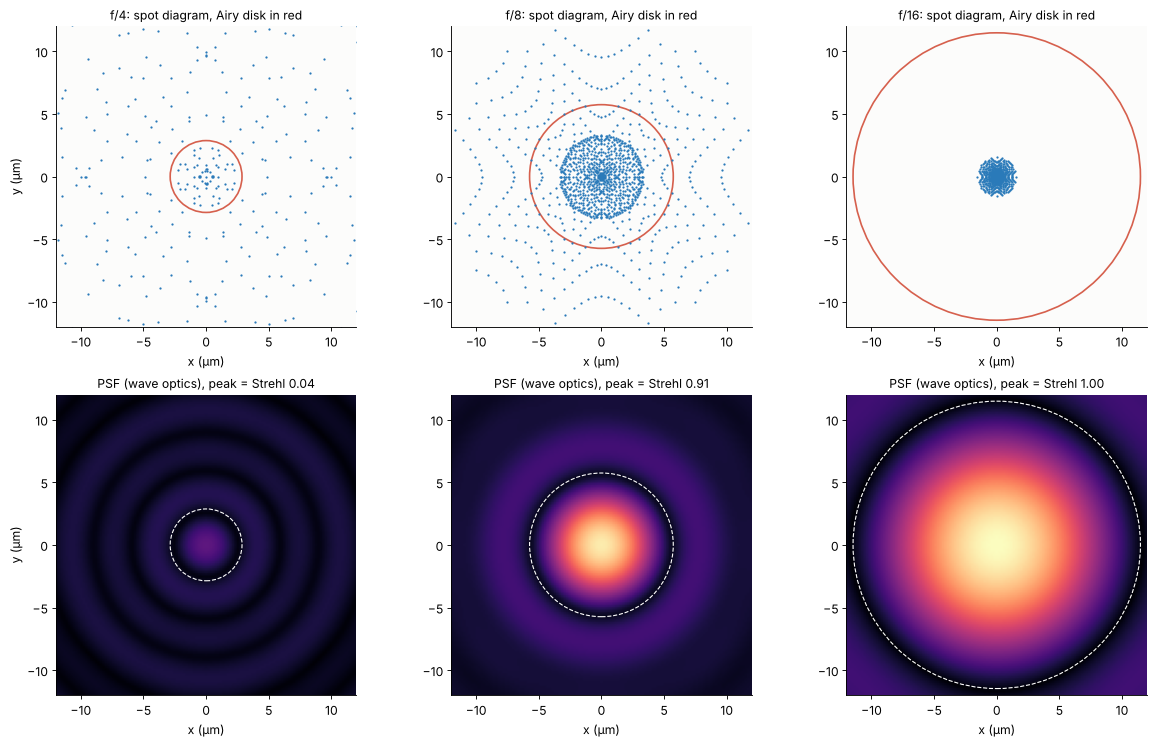

In [25]:
show = (4, 8, 16)
fig, ax = plt.subplots(2, 3, figsize=(15, 9.2), layout="constrained")
for j, N in enumerate(show):
    S = rows[list(f_numbers).index(N)][3]
    r_airy = 1.22*lam*N
    sp = S.spot_diagram(0.0, N=41)
    half = 12e-3                                    # mm, the same window for all three
    ax[0, j].plot(sp.x*1e3, sp.y*1e3, ".", color=BLUE, ms=2)
    ax[0, j].add_patch(mpatches.Circle((0, 0), r_airy*1e3, fill=False, color=RED, lw=1.5))
    ax[0, j].set_xlim(-half*1e3, half*1e3)
    ax[0, j].set_ylim(-half*1e3, half*1e3)
    ax[0, j].set_aspect("equal")
    ax[0, j].set_title("f/{}: spot diagram, Airy disk in red".format(N), fontsize=11)
    ax[0, j].set_xlabel("x (µm)")
    x = np.linspace(-0.1, 0.1, 1024, endpoint=False)
    I = np.abs(S.psf(x, x, 0.0, N=96))**2
    ax[1, j].imshow(I, extent=(x[0]*1e3, x[-1]*1e3, x[0]*1e3, x[-1]*1e3), origin="lower", cmap="magma",
                    norm=PowerNorm(0.4, vmin=0, vmax=1))
    ax[1, j].add_patch(mpatches.Circle((0, 0), r_airy*1e3, fill=False, color="w", lw=1, ls="--"))
    ax[1, j].set_xlim(-half*1e3, half*1e3)
    ax[1, j].set_ylim(-half*1e3, half*1e3)
    ax[1, j].set_title("PSF (wave optics), peak = Strehl {:.2f}".format(I.max()), fontsize=11)
    ax[1, j].set_xlabel("x (µm)")
ax[0, 0].set_ylabel("y (µm)")
ax[1, 0].set_ylabel("y (µm)")
plt.show()

The Strehl ratio of the traced lens follows Maréchal's formula down to
$S \approx 0.4$ ($\sigma \approx 0.15$ waves); for larger errors the
formula underestimates it (at f/4 it gives $10^{-11}$ against 0.04).
The singlet becomes diffraction limited ($S = 0.8$) at about f/7.3. Its
rms spot radius from geometrical optics falls with $1/N^3$ and crosses the
Airy radius near f/8: below that, ray optics alone would overstate the
blur of the image, and the spot diagram stops being a picture of the
point image. At f/4 the spot is 15 times larger than the Airy disk, and
the PSF shows a weak core with most of the light spread into rings; at
f/16 all rays land well inside the Airy disk, and the image is the Airy
pattern of notebook 17 (PSF, MTF and Strehl), set by diffraction alone.

This is the limit of geometrical optics: it designs the lens and
computes its wavefront error; the image itself is a question for wave
optics. Notebooks 15 (imaging and Zernikes) and 17 (PSF, MTF and Strehl) take over from here.

## Summary

- **Paraxial optics** linearizes Snell's law, $n\,i = n'\,i'$. One sphere
  focuses parallel rays at $n'R/(n' - n)$ (58.70 mm, trace and formula),
  but real rays at 12 mm height focus 5 mm short: spherical aberration.
- **Thin lens:** $1/a' - 1/a = 1/f$, $m = a'/a$ (Cartesian signs;
  $1/s_o + 1/s_i = 1/f$ with positive object distances), lensmaker's
  $1/f = (n - 1)(1/R_1 - 1/R_2)$. The ideal lens of the ray tracer
  reproduces them to $10^{-15}$, for real and for virtual images.
- **Real and virtual images:** three principal rays construct every
  image; objects outside $F$ give real inverted images (camera,
  projector), inside $F$ upright virtual ones (magnifier), a diverging
  lens always an upright reduced virtual image.
- **Principal planes:** with distances measured from $H$ and $H'$, any
  system obeys the thin lens equation (checked for a 12 mm thick lens:
  $f' = 60.10$ mm against 58.05 mm thin). They can lie outside the glass:
  a telephoto pair of 300 mm focal length is 180 mm long. For real rays
  they become curved principal surfaces, a sphere around $F'$ for a lens
  that obeys the sine condition.
- **Stops and pupils:** the aperture stop and its images, the entrance
  and exit pupils, define the marginal and the chief ray; f-number
  $N = f'/D$, $\mathrm{NA} = n'\sin U' \approx 1/(2N)$.
- **Instruments:** magnifier $M = 250\,\text{mm}/f$ (or $+1$), microscope
  $M = -(L/f_\text{obj})(250\,\text{mm}/f_\text{ep}) = -100$, telescope
  $M = -f_o/f_e = \mp 20$ (Kepler/Galilei), exit pupil $D/|M|$, all
  reproduced by the ray tracer from the angle of the chief ray into the
  eye.
- **Seidel sums:** spherical aberration, coma, astigmatism, field curvature
  and distortion; `System.seidel()` agrees with the traced OPD within
  0.5 % at f/8. A singlet has least spherical aberration bent to
  $X \approx 0.74$–$0.80$ and is free of coma at nearly the same shape;
  the plano-convex lens the wrong way round has four times the
  spherical aberration. Moving the stop changes coma, astigmatism and
  distortion but not the spherical aberration.
- **Wavefront error:** defocus balances spherical aberration and cuts
  the rms by four; Strehl $\approx \exp[-(2\pi\sigma)^2]$; diffraction
  limited means $\sigma \le \lambda/14$ (Strehl 0.8), reached by the
  f = 100 mm singlet from f/7.3 on, where its geometrical spot shrinks
  below the Airy disk.

## References

E. Hecht, *Optics*, 5th ed., Pearson (2017), chapters 5 and 6.

W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008).

W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986).

R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed.,
Academic Press (2010).

M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge
University Press (1999), chapters 4, 5 and 9.

V. N. Mahajan, *Optical Imaging and Aberrations, Part I: Ray Geometrical
Optics*, SPIE Press (1998).

In [26]:
print("notebook run time {:.0f} s".format(time.time() - t_start))

notebook run time 8 s
